# 03. Целевая переменная: что именно прогнозируем

**Что делаем.** Сервис должен за 24 часа предупредить диспетчера об инциденте в коллекторе и указать место.
Журнала подтвержденных инцидентов (журнала ОДС) у нас нет, есть только журнал событий СМВУ: замеры и смены
состояний датчиков за 2019-2026 годы. Значит, «инцидент» для обучения модели нужно определить самим из этого
журнала. От определения зависит все остальное: чему учится модель, с чем сравнивается прогноз, какие цифры
точности мы покажем. Поэтому ниже мы не назначаем целевую переменную, а выбираем ее: формулируем критерии,
рассматриваем варианты и каждый выбор проверяем расчетом на данных.

**Как устроен ноутбук.**

0. Задача, критерии хорошей целевой переменной, объем данных
1. Что считать тревогой: флаг системы, словарь состояний или их сочетание
2. Из записей в эпизоды
3. Дребезг: какие эпизоды слишком короткие, чтобы быть инцидентом
4. Работы бригад и ложные отказы
5. Потеря связи
6. Маски и эпохи: какие дни нельзя использовать, включая плановые работы аппаратуры контроля метана
7. Классы, сетка и горизонт прогноза
8. Предсказуемость
9. Разбиение по времени
10. Итог: целевая переменная

Все времена московские.

In [1]:
import hashlib
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from pyspark.sql import Window
from pyspark.sql import functions as F

from annanas import aggregates as agg
from annanas import episodes as ep
from annanas import maintenance as mt
from annanas import smvu
from annanas import target as tg
from annanas.paths import EDA_DIR, EVENTS_DIR, PROCESSED_DIR
from annanas.spark import get_spark

spark = get_spark("03_target")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")  # быстрый toPandas
spark.conf.set("spark.sql.shuffle.partitions", "400")  # окна по каналу на сотнях миллионов строк
EP_DIR = PROCESSED_DIR / "episodes"
EP_DIR.mkdir(parents=True, exist_ok=True)
MAINT_DIR = PROCESSED_DIR / "maintenance"  # дни тестового газа и окна плановых работ (раздел 6.4)
MAINT_DIR.mkdir(parents=True, exist_ok=True)

events = spark.read.parquet(str(EVENTS_DIR))
channels = spark.read.parquet(str(PROCESSED_DIR / "channels.parquet"))
channels_pd = channels.toPandas()

START, END = pd.Timestamp("2019-01-01"), pd.Timestamp("2026-06-30")  # полные журналы: 2019-01-01 … 2026-06-30
YEARS = range(2019, 2027)

pd.set_option("display.max_rows", 150)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/26 03:33:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/09/26 03:33:38 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


In [2]:
# Оформление графиков: фиксированная категориальная палитра, тонкие линии, приглушенные оси
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY, SHADE, INK, INK2 = "#9a9994", "#c9c7bf", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "lines.linewidth": 1.5, "axes.prop_cycle": plt.cycler(color=PALETTE),
})
SOURCE_COLOR = {"флаг": PALETTE[1], "словарь": PALETTE[3], "пары": PALETTE[0]}


def thousands(ax, axis="y"):
    f = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def pct(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mticker.PercentFormatter(1.0))


def n(v) -> str:
    """Число с пробелом-разделителем тысяч."""
    return f"{v:,.0f}".replace(",", " ")


def average_precision(y, score) -> float:
    """PR-AUC (average precision): площадь под кривой точность-полнота, одинаковые оценки – один порог."""
    d = pd.DataFrame({"y": np.asarray(y, dtype=float), "s": np.asarray(score, dtype=float)}).dropna()
    g = d.groupby("s", sort=True)["y"].agg(["sum", "count"]).iloc[::-1]
    tp, cnt = g["sum"].cumsum(), g["count"].cumsum()
    recall = tp / d["y"].sum()
    return float((recall.diff().fillna(recall) * (tp / cnt)).sum())

## 0. Задача и критерии

**Что требует ТЗ.** Сервис прогнозирует инциденты в коллекторах: отказы оборудования и датчиков, пожар,
подтопление, проникновение (для проникновения ТЗ просит поддержку верификации, а не прогноз). Прогноз должен
давать **вероятность** инцидента, **горизонт не меньше 24 часов**, **локацию** (объект, пикет) и **тип**
инцидента. Экспертиза сравнит прогноз с реальными значениями, а целевые точность и полноту определяет команда.
Журнала ОДС с подтвержденными инцидентами, решениями диспетчера и ложными срабатываниями нет: целевую
переменную строим только из журнала событий.

Отсюда шесть критериев хорошей целевой переменной. Ниже каждый проверяется расчетом, а в конце сведен в таблицу.

1. **Тип.** Соответствует типам инцидентов из ТЗ.
2. **Реальность.** Отражает реальное событие в коллекторе, а не дребезг датчика, плановые работы бригад или
   артефакт сбора данных.
3. **Единообразие.** Одинаково размечена во всем периоде 2019-2026. Если правило разметки меняется во времени,
   модель выучит смену правила, а не инциденты.
4. **Локация.** Привязана к объекту и, где возможно, к пикету.
5. **Объем.** Положительных примеров хватает и для обучения, и для честной проверки на отложенном периоде.
6. **Предсказуемость.** Прогнозируется на 24 часа вперед лучше случайного угадывания.

### 0.1 Данные
Журнал событий уже очищен и лежит в Parquet по годам и месяцам: каждая запись – это либо замер (число),
либо смена состояния (текст: «Норма», «Неисправен», «Обнаружен дым» …) с флагом `тревожное`, который
проставляет сама СМВУ. Справочник каналов дает тип датчика, объект и пикет. Посмотрим на объем.

In [3]:
daily_channel = spark.read.parquet(str(EDA_DIR / "daily_channel.parquet"))  # записи канала за сутки
volume = (daily_channel.groupBy(F.year("день").alias("год"), "класс_записи")
          .agg(F.sum("количество_событий").alias("записей")).toPandas()
          .pivot(index="год", columns="класс_записи", values="записей").fillna(0).astype("int64"))
volume["всего"] = volume.sum(axis=1)
display(volume)
known = set(channels_pd["ид_канала_данных"])
journal_channels = set(daily_channel.select("ид_канала_данных").distinct().toPandas()["ид_канала_данных"])
print(f"записей всего: {n(volume['всего'].sum())}, из них смен состояния: {n(volume['состояние'].sum())}")
print(f"каналов в справочнике: {n(len(channels_pd))}, объектов: {channels_pd['ид_объект'].nunique()}, "
      f"каналов с пикетом: {channels_pd['пикет'].notna().mean():.1%}")
print(f"каналов в журнале: {n(len(journal_channels))}, из них нет в справочнике: "
      f"{n(len(journal_channels - known))}")

класс_записи,измерение,состояние,всего
год,,,
2019,9626993,11364844,20991837
2020,12920153,15252245,28172398
2021,36076170,17622778,53698948
2022,33875898,9607251,43483149
2023,22662927,8711749,31374676
2024,39085453,9938430,49023883
2025,45790871,9750925,55541796
2026,24705860,5989529,30695389


записей всего: 312 982 076, из них смен состояния: 88 237 751
каналов в справочнике: 11 485, объектов: 78, каналов с пикетом: 93.3%
каналов в журнале: 12 627, из них нет в справочнике: 1 142


В журнале 312 982 076 записей, из них 88 237 751 – смены состояний: именно в них живут тревоги, из которых мы
будем строить целевую. Справочник описывает 11 485 каналов на 78 объектах, у 93,3 % каналов
есть пикет. Еще 1 142 каналов пишут в журнал, но в справочнике их нет: у них неизвестны ни тип датчика,
ни объект, поэтому ни класс инцидента, ни локацию для них определить нельзя, и в целевую они не входят.

Тяжелые расчеты по журналу делаем один раз в Spark и кэшируем в `datasets/processed/episodes/`.
Первая витрина – поток смен состояния в разрезе «тип датчика × состояние × сутки × час суток» с числом
записей и числом записей с флагом `тревожное`. Она понадобится, чтобы понять, как СМВУ размечает тревоги.

In [4]:
flag_hourly = agg.build_or_load("flag_hourly", lambda: (
    events.filter(F.col("класс_записи") == "состояние")
    .join(F.broadcast(channels.select("ид_канала_данных", "тип_датчика")), "ид_канала_данных")
    .groupBy("тип_датчика", "состояние", F.to_date("дата_время").alias("день"),
             F.hour("дата_время").alias("час_суток"))
    .agg(F.count("*").alias("количество_событий"),
         F.sum(F.col("тревожное").cast("int")).alias("количество_тревожных"))), EP_DIR, spark)
fh = flag_hourly.toPandas()
fh["день"] = pd.to_datetime(fh["день"])
fh["количество_тревожных"] = fh["количество_тревожных"].fillna(0)
fh["месяц"] = fh["день"].dt.to_period("M").dt.to_timestamp()
fh["класс"] = [ep.state_class(т, с) for т, с in zip(fh["тип_датчика"], fh["состояние"])]
print(f"строк витрины: {n(len(fh))}, записей: {n(fh['количество_событий'].sum())}")

строк витрины: 1 135 513, записей: 79 757 657


## 1. Что считать тревогой

Есть два естественных источника. **Флаг** `тревожное`: система сама решает, что запись тревожная. **Словарь
состояний**: мы решаем по тексту состояния и типу датчика («Неисправен» – отказ, «Затоплен» – подтопление,
«Обнаружен дым» – пожар и т. д.). Сначала проверим, можно ли доверять флагу (критерий 3 – единообразие).

### 1.1 Меняется ли разметка флага во времени
Возьмем состояния, которые по смыслу однозначно тревожные, и посмотрим, какую долю их записей система
помечала флагом месяц за месяцем. Если флаг – устойчивое свойство состояния, доля должна быть ровной.

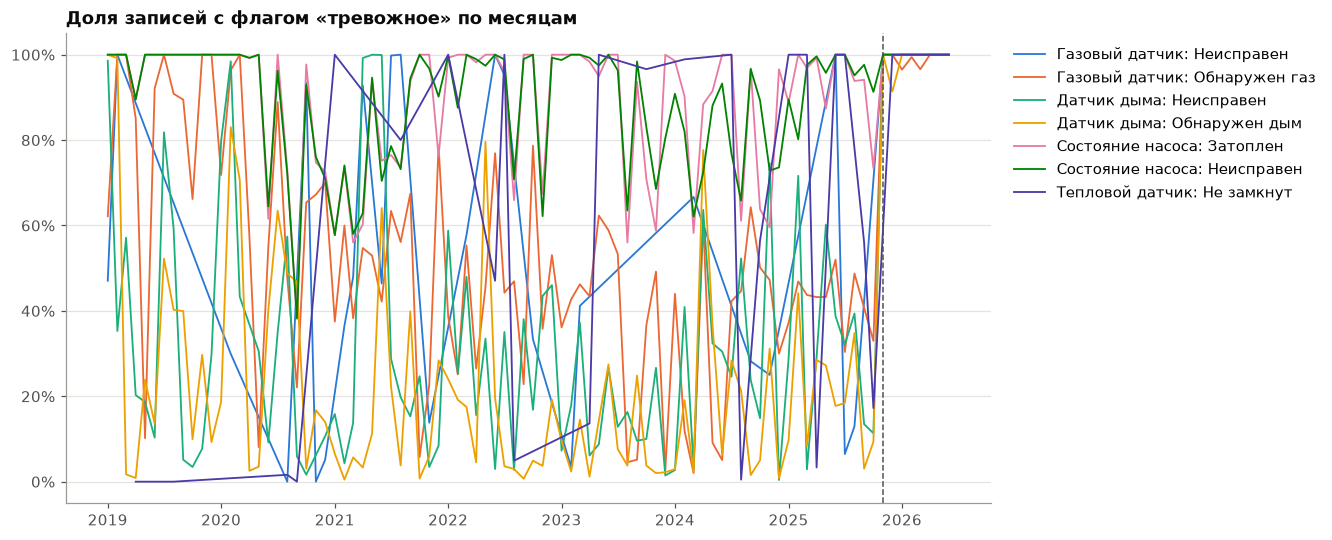

год                             2019  2020  2021  2022  2023  2024  2025  2026
тип_датчика      состояние                                                    
Газовый датчик   Неисправен    0.760 0.210 0.930 0.670 0.330 0.390 0.950 1.000
                 Обнаружен газ 0.890 0.640 0.510 0.450 0.370 0.340 0.580 0.990
Датчик дыма      Неисправен    0.250 0.790 1.000 0.130 0.140 0.180 0.490 1.000
                 Обнаружен дым 0.350 0.490 0.150 0.120 0.070 0.100 0.300 1.000
Состояние насоса Затоплен      1.000 0.800 0.730 0.910 0.820 0.710 0.940 1.000
                 Неисправен    1.000 0.820 0.780 0.940 0.900 0.770 0.960 1.000
Тепловой датчик  Не замкнут    0.250 0.010 0.830 0.660 0.680 0.450 0.830 1.000

In [5]:
KEY = [("Датчик дыма", "Обнаружен дым"), ("Датчик дыма", "Неисправен"), ("Газовый датчик", "Обнаружен газ"),
       ("Газовый датчик", "Неисправен"), ("Состояние насоса", "Затоплен"), ("Состояние насоса", "Неисправен"),
       ("Тепловой датчик", "Не замкнут")]


def is_key(df, pairs=KEY):
    return pd.MultiIndex.from_frame(df[["тип_датчика", "состояние"]]).isin(pairs)


key = fh[is_key(fh)]
monthly_flag = (key.groupby(["тип_датчика", "состояние", "месяц"])[["количество_событий", "количество_тревожных"]]
                .sum())
monthly_flag["доля_флага"] = monthly_flag["количество_тревожных"] / monthly_flag["количество_событий"]
fig, ax = plt.subplots(figsize=(12, 4.8))
for (т, с), g in monthly_flag.groupby(level=[0, 1]):
    g = g[g["количество_событий"] >= 20]  # доля по месяцу с десятком записей неинформативна
    ax.plot(g.index.get_level_values("месяц"), g["доля_флага"], label=f"{т}: {с}", lw=1.2)
ax.axvline(pd.Timestamp("2025-11-01"), color=INK2, ls="--", lw=1)
ax.set_title("Доля записей с флагом «тревожное» по месяцам")
pct(ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
yearly_flag = (key.assign(год=key["день"].dt.year)
               .groupby(["тип_датчика", "состояние", "год"])[["количество_событий", "количество_тревожных"]].sum())
display((yearly_flag["количество_тревожных"] / yearly_flag["количество_событий"]).unstack("год").round(2))

**Наблюдение.** Доля флага у одного и того же состояния сильно гуляет по годам. «Обнаружен дым» дымового датчика
помечен флагом в 35 % записей в 2019 году, в 7 % в 2023-м, в 30 % в 2025-м и в 100 % в 2026-м.
«Обнаружен газ» – от 89 % в 2019-м до 34 % в 2024-м и 99 % в 2026-м. Даже у «Затоплен» насоса доля ходит
между 71 % и 100 %. В конце 2025 года все линии на графике сходятся к 100 %.

**Гипотеза.** Флаг – не свойство состояния, а решение системы, правила которого менялись. Если строить цель
по флагу, модель увидит в конце 2025 года ложный рост инцидентов. Проверим это ниже на эпизодах, а пока найдем
точную дату смены.

Найдем день смены разметки точно. Ночью флаг, как покажет следующий раздел, стоит почти всегда, поэтому
смотрим дневные часы (9-16), где разница между «до» и «после» максимальна. Для каждого дня-кандидата
сравниваем среднюю дневную долю флага за 30 дней до и 30 дней после; граница – день с наибольшим скачком.

In [6]:
day = key[key["час_суток"].between(9, 16)].groupby("день")[["количество_событий", "количество_тревожных"]].sum()
day = day.reindex(pd.date_range("2025-06-01", "2026-03-31"), fill_value=0)
share = day["количество_тревожных"] / day["количество_событий"].replace(0, np.nan)
jump = pd.Series({d: share[d:d + pd.Timedelta(days=29)].mean() - share[d - pd.Timedelta(days=30):
                                                                      d - pd.Timedelta(days=1)].mean()
                  for d in share.index[30:-30]})
FLAG_CHANGE = jump.idxmax()
assert FLAG_CHANGE == tg.FLAG_CHANGE  # дата в annanas.target (столбец эпоха_флага в сервисе)
print(f"день смены разметки флага: {FLAG_CHANGE:%Y-%m-%d}, скачок дневной доли: {jump.max():+.2f}")
display(pd.DataFrame({"записей_днем": day["количество_событий"], "доля_флага_днем": share.round(2)})
        .loc[FLAG_CHANGE - pd.Timedelta(days=7):FLAG_CHANGE + pd.Timedelta(days=7)].T)
STABLE_UNTIL = FLAG_CHANGE.to_period("M").to_timestamp()  # полные месяцы до смены разметки
print(f"период устойчивой разметки для оценки пар: месяцы до {STABLE_UNTIL:%Y-%m-%d}")

день смены разметки флага: 2025-10-29, скачок дневной доли: +0.42


,2025-10-22,2025-10-23,2025-10-24,2025-10-25,2025-10-26,2025-10-27,2025-10-28,2025-10-29,2025-10-30,2025-10-31,2025-11-01,2025-11-02,2025-11-03,2025-11-04,2025-11-05
записей_днем,68.000,263.000,100.000,0.000,0.000,0.000,0.000,6.000,280.000,38.000,41.000,11.000,0.000,5.000,27.000
доля_флага_днем,0.990,0.900,0.590,NaN,NaN,NaN,NaN,1.000,0.800,1.000,1.000,1.000,NaN,1.000,1.000


период устойчивой разметки для оценки пар: месяцы до 2025-10-01


**Результат.** Наибольший скачок дневной доли флага (+0,42) приходится на **2025-10-29**. Дневных записей
ключевых состояний в эти дни мало, а с 25 по 28 октября их нет совсем, поэтому точность даты – несколько дней:
24 октября доля еще 0,59, с 29 октября она не опускается ниже 0,8, а в большинстве дней равна 1. Дальше
«до смены» – это полные месяцы до 2025-10-01 (период устойчивой разметки), «после смены» – с 2025-10-29.

### 1.2 Флаг в течение суток
Дрейф флага по годам можно объяснить по-разному: сменой настроек, другим составом датчиков, другими объектами.
Проверим еще одно измерение – час суток. Если флаг отражает только природу состояния, доля не должна зависеть
от времени дня.

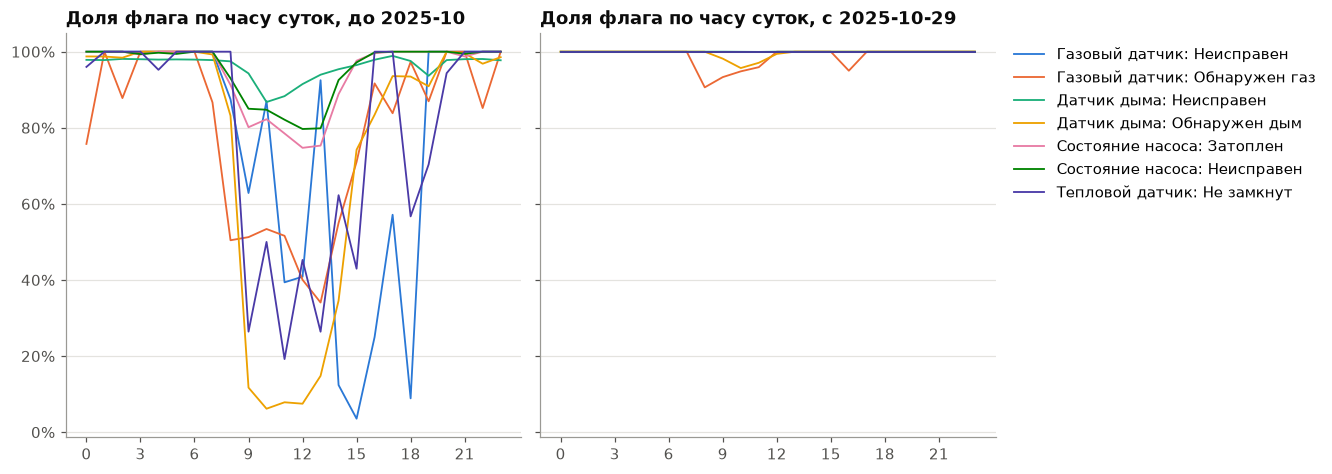

до смены                   после смены           
                       количество_событий доля_флага количество_событий доля_флага
часы      рабочий_день                                                            
день 9-16 False                    109098      0.990              11710      1.000
          True                     556671      0.677              82626      0.994
ночь 0-6  False                     96070      0.999               8618      1.000
          True                     238184      0.973              11237      1.000
прочие    False                    119255      0.996               9737      1.000
          True                     310156      0.965              18148      1.000

In [7]:
before = key[key["день"] < STABLE_UNTIL]
after = key[key["день"] >= FLAG_CHANGE]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, part, title in [(axes[0], before, f"до {STABLE_UNTIL:%Y-%m}"), (axes[1], after, f"с {FLAG_CHANGE:%Y-%m-%d}")]:
    g = part.groupby(["тип_датчика", "состояние", "час_суток"])[["количество_событий", "количество_тревожных"]].sum()
    for (т, с), x in g.groupby(level=[0, 1]):
        ax.plot(x.index.get_level_values("час_суток"), x["количество_тревожных"] / x["количество_событий"],
                label=f"{т}: {с}", lw=1.2)
    ax.set_title(f"Доля флага по часу суток, {title}")
    ax.set_xticks(range(0, 24, 3))
    pct(ax)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()


def by_slot(part):
    """Доля флага по слотам «ночь / день 9-16 / прочие» × рабочий день."""
    x = part.assign(рабочий_день=part["день"].dt.dayofweek < 5,
                    часы=np.select([part["час_суток"] < 7, part["час_суток"].between(9, 16)],
                                   ["ночь 0-6", "день 9-16"], "прочие"))
    g = x.groupby(["часы", "рабочий_день"])[["количество_событий", "количество_тревожных"]].sum()
    return g.assign(доля_флага=g["количество_тревожных"] / g["количество_событий"])[["количество_событий", "доля_флага"]]


display(pd.concat({"до смены": by_slot(before), "после смены": by_slot(after)}, axis=1).round(3))

**Результат.** До смены разметки флаг ночью (0-6 ч) стоит почти всегда: 97,3 % записей в будни и 99,9 %
в выходные. Днем с 9 до 16 в выходные – 99,0 %, а в будни – только 67,7 %. После смены разметки доля
во всех слотах 99,4-100 %.

**Вывод.** Флаг до конца октября 2025 года зависел от расписания: в будни в рабочее время тревоги часто не
помечались. Наиболее правдоподобное объяснение – режим работ или обслуживания, в котором СМВУ не считает
срабатывание тревогой; подтвердить это без графика работ мы не можем. Этим объясняется и дрейф по годам:
доля флага за год зависит от того, какая часть срабатываний пришлась на рабочие часы. После смены разметки
это подавление исчезло. Значит, флаг непригоден как целевая сразу по двум причинам: он зависит от часа
суток и меняет правило в конце 2025 года. Но ночной флаг полезен: ночью подавления нет, и по нему видно,
какие состояния сама система считает тревогой.

### 1.3 Словарь состояний
Теперь второй источник. Словарь «тип датчика + состояние → класс» задан в `annanas.episodes`. Состояние
«Не замкнут» значит разное у разных типов: у датчика затопления это вода, у теплового и ручного извещателя –
пожар, у контактных датчиков (двери, люки) – открыто. Классы: отказ, подтопление, пожар, газ, проникновение
и неисправность охраны (состояние «Много неисправных устройств» у канала «Состояние охраны»; почему это не
отказ, а отдельный класс, проверяем в разделах 7.1 и 8); еще два служебных – «откачка» (работают все насосы
АНС) и «вывод из работы» (отключено устройство). Таблица ниже –
все пары с классом, их объем и доля флага в период устойчивой разметки (весь день и ночью, 0-6 ч) и после смены.

In [8]:
NIGHT_END = 7  # ночь: 0:00-6:59
fh["ночь"] = fh["час_суток"] < NIGHT_END
fh["период"] = np.select([fh["день"] < STABLE_UNTIL, fh["день"] >= FLAG_CHANGE], ["до", "после"], "граница")


def flag_table(df):
    def part(mask, suffix):
        g = df[mask].groupby(["тип_датчика", "состояние"])[["количество_событий", "количество_тревожных"]].sum()
        return pd.DataFrame({f"записей_{suffix}": g["количество_событий"],
                             f"доля_флага_{suffix}": g["количество_тревожных"] / g["количество_событий"]})
    t = pd.concat([part(df["период"] == "до", "до"), part((df["период"] == "до") & df["ночь"], "до_ночью"),
                   part(df["период"] == "после", "после")], axis=1)
    t.insert(0, "класс", [ep.state_class(т, с) for т, с in t.index])
    return t.fillna({c: 0 for c in t.columns if c.startswith("записей")})


vocab = flag_table(fh)
with_class = vocab[vocab["класс"].isin(ep.EPISODE_CLASSES)].sort_values(["класс", "записей_до"],
                                                                         ascending=[True, False])
display(with_class)

,,класс,записей_до,доля_флага_до,записей_до_ночью,доля_флага_до_ночью,записей_после,доля_флага_после
тип_датчика,состояние,,,,,,,
Датчик дыма,Отключено устройство,вывод_из_работы,1 804.000,0.703,30.000,1.000,2 151.000,1.000
Датчик движения,Отключено устройство,вывод_из_работы,866.000,0.338,5.000,1.000,213.000,0.268
Состояние УИР-Р,Отключено устройство,вывод_из_работы,266.000,0.526,3.000,1.000,283.000,0.996
КД АВ,Отключено устройство,вывод_из_работы,125.000,1.000,9.000,1.000,257.000,1.000
Газовый датчик,Отключено устройство,вывод_из_работы,79.000,0.823,10.000,1.000,47.000,1.000
КД Дверь,Отключено устройство,вывод_из_работы,47.000,0.213,2.000,0.000,171.000,0.591
Датчик температуры,Отключено устройство,вывод_из_работы,31.000,1.000,2.000,1.000,115.000,1.000
КД Люк,Отключено устройство,вывод_из_работы,29.000,1.000,5.000,1.000,6.000,1.000
Переключатель,Отключено устройство,вывод_из_работы,22.000,0.909,2.000,1.000,456.000,1.000


**Наблюдение.** У большинства пар с классом ночная доля флага близка к 1 (у «Неисправен» дымового датчика
0,979 на 310 068 ночных записях, у насосов и вентиляторов 0,995-0,997). Но есть пары, которые словарь
относит к тревогам, а система не считает тревогой никогда или почти никогда:
- «Состояние фазы: Обесточен» – 992 828 записей до смены и ни одной с флагом, даже ночью. Это нормальное
  переключение («Обесточен» / «Есть питание»), а не отказ;
- «Датчик движения: Обнаружено движение» и «КД Дверь: Не замкнут» – классы «проникновение», миллионы записей
  и доля флага даже ночью 0,245 и 0,063 (таблица в разделе 1.4).

Значит, чистый словарь завышает тревоги: в «отказ» попадут ежедневные переключения фазы, в «проникновение» –
каждое срабатывание датчика движения.

Обратная проверка: есть ли состояния, которые система помечает тревожными, а словарь оставляет без класса.

In [9]:
no_class = vocab[vocab["класс"].isna()].copy()
no_class["тревожных_до"] = (no_class["записей_до"] * no_class["доля_флага_до"].fillna(0)).round()
no_class["тревожных_после"] = (no_class["записей_после"] * no_class["доля_флага_после"].fillna(0)).round()
display(no_class[(no_class["тревожных_до"] + no_class["тревожных_после"]) > 0]
        .sort_values("тревожных_до", ascending=False).drop(columns="класс"))

записей_до  доля_флага_до  записей_до_ночью  доля_флага_до_ночью  записей_после  доля_флага_после  тревожных_до  тревожных_после
тип_датчика        состояние                                                                                                                                              
Датчик температуры Температура ниже 3ºC    9 021.000          0.869         1 100.000                0.975        949.000             1.000     7 836.000          949.000
                   Температура выше 40ºC   1 855.000          0.763            59.000                0.949         93.000             1.000     1 415.000           93.000
Датчик движения    Не замкнут             99 389.000          0.002            48.000                0.521          0.000               NaN       197.000            0.000
Датчик дыма        Не замкнут                236.000          0.106            11.000                0.909         12.000             1.000        25.000           12.000
Состояние УИР-Р    Не замкнут              1 188.000          0.006             0.000                  NaN        136.000             1.000         7.000          136.000
Состояние фазы     Не замкнут                  3.000          1.000             0.000                  NaN          0.000               NaN         3.000            0.000
ИБП                Не замкнут                  2.000          1.000             0.000                  NaN          0.000               NaN         2.000            0.000
Газовый датчик     Не замкнут                  1.000          1.000             0.000                  NaN          0.000               NaN         1.000            0.000
Состояние фазы     Температура ниже 3ºC        1.000          1.000             0.000                  NaN          0.000               NaN         1.000            0.000

**Результат.** Заметный объем тревожных по флагу записей без класса есть только у «Температура ниже 3ºC»
(9 021 запись, 86,9 % с флагом) и «Температура выше 40ºC» (1 855, 76,3 %). Это климат коллектора, а не тип
инцидента из ТЗ, поэтому они оставлены без класса осознанно и пойдут в признаки. «Не замкнут» у датчика
движения, дыма и УИР-Р помечен флагом в 0,2-10,6 % записей до смены, смысл шлейфа у этих типов неясен,
а тревожных записей десятки-сотни. Пропущенных тревожных состояний, которые меняли бы картину, нет.

### 1.4 Третий вариант: пары, которые считает тревожными сама система
Словарь завышает тревоги (нормальные переключения фазы, движение, открытые двери), флаг непостоянен во времени.
Сочетание: берем из словаря только те пары «тип + состояние», которые сама СМВУ в период устойчивой разметки
помечала тревожными в большинстве записей, а дальше флаг не смотрим. Такой источник не зависит от смены
разметки (список пар фиксирован) и не включает нормальные переключения.

Нужен порог «в большинстве записей». Посмотрим, как распределены доли флага по парам: если пары делятся на две
группы (почти никогда не тревожные и почти всегда тревожные), порог можно поставить в пустом промежутке.
Считаем доли двумя способами: за весь день и только ночью, где, по разделу 1.2, флаг не подавляется.

,"[0.0, 0.1)","[0.1, 0.2)","[0.2, 0.3)","[0.3, 0.4)","[0.4, 0.5)","[0.5, 0.6)","[0.6, 0.7)","[0.7, 0.8)","[0.8, 0.9)","[0.9, 0.95)","[0.95, 1.0)"
пар_весь_день,4,1,0,0,0,2,2,1,7,0,10
пар_ночью,2,1,1,0,0,0,0,0,1,1,21


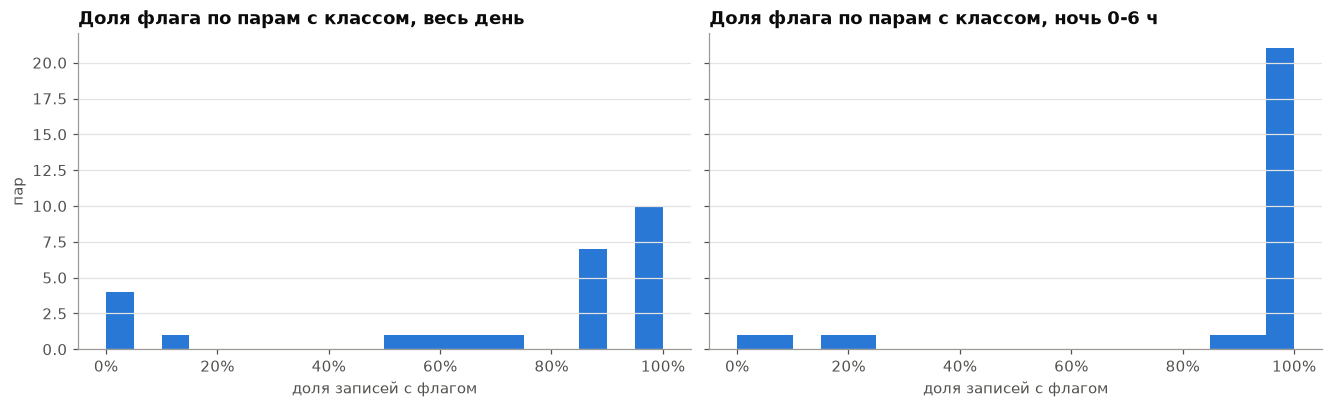

In [10]:
MIN_NIGHT_RECORDS = 30  # по 30 записям доля оценивается с точностью около ±0,1
cand = with_class[with_class["записей_до_ночью"] >= MIN_NIGHT_RECORDS]
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0001]
hist = pd.DataFrame({"пар_весь_день": pd.cut(cand["доля_флага_до"], bins, right=False).value_counts(sort=False),
                     "пар_ночью": pd.cut(cand["доля_флага_до_ночью"], bins, right=False).value_counts(sort=False)})
display(hist.T)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, col, title in [(axes[0], "доля_флага_до", "весь день"), (axes[1], "доля_флага_до_ночью", "ночь 0-6 ч")]:
    ax.hist(cand[col], bins=np.linspace(0, 1, 21), color=PALETTE[0])
    ax.set_title(f"Доля флага по парам с классом, {title}")
    ax.set_xlabel("доля записей с флагом")
    pct(ax, "x")
axes[0].set_ylabel("пар")
plt.show()

**Результат.** Из 27 пар с классом и не меньше чем 30 ночными записями по доле за весь день 12 пар попадают
в середину, от 0,5 до 0,9: дневное подавление размывает картину. Ночью распределение четко двухгорбое:
4 пары ниже 0,3, ни одной пары между 0,3 и 0,8, остальные 23 выше 0,8 (21 – выше 0,95). Порог 0,5 стоит
в середине пустого промежутка: любое значение от 0,3 до 0,8 дает тот же список пар. Минимум 30 ночных записей
нужен, чтобы доля по паре не была случайной.

In [11]:
MIN_SHARE = 0.5


def vocab_for_pairs(part):
    """Витрина в формате state_vocab (тип, состояние, тревожное, год, месяц, количество_событий) из flag_hourly."""
    g = (part.assign(год=part["день"].dt.year, месяц=part["день"].dt.month)
         .groupby(["тип_датчика", "состояние", "год", "месяц"], as_index=False)
         [["количество_событий", "количество_тревожных"]].sum())
    yes = g.assign(тревожное=True, количество_событий=g["количество_тревожных"])
    no = g.assign(тревожное=False, количество_событий=g["количество_событий"] - g["количество_тревожных"])
    return pd.concat([yes, no]).drop(columns="количество_тревожных")


pairs = ep.alarm_pairs(vocab_for_pairs(fh[fh["ночь"]]), STABLE_UNTIL, min_share=MIN_SHARE,
                       min_records=MIN_NIGHT_RECORDS)
PAIRS = list(zip(pairs["тип_датчика"], pairs["состояние"]))
display(pairs.rename(columns={"доля_флага": "доля_флага_ночью", "записей": "записей_ночью"}))
dropped = with_class[~with_class.index.isin(PAIRS)].copy()
dropped["причина"] = np.where(dropped["записей_до_ночью"] < MIN_NIGHT_RECORDS, "мало записей ночью",
                              "ночью флаг редко")
dropped["записей_всего"] = dropped["записей_до"] + dropped["записей_после"]
display(dropped[["класс", "записей_всего", "записей_до_ночью", "доля_флага_до_ночью", "причина"]]
        .sort_values("записей_всего", ascending=False))
tot_cls = with_class["записей_до"].sum() + with_class["записей_после"].sum()
print(f"пар в списке: {len(PAIRS)}; исключено пар: {len(dropped)}, "
      f"это {dropped['записей_всего'].sum() / tot_cls:.1%} записей с классом по словарю")
for c in ep.TARGET_CLASSES:
    kept = pairs.loc[pairs["класс"] == c]
    print(f"{c}: пар в списке {len(kept)}")

,тип_датчика,состояние,класс,доля_флага_ночью,записей_ночью
0,Газовый датчик,Неисправен,отказ,1.000,200
1,Газовый датчик,Обнаружен газ,газ,0.935,201
2,Датчик движения,Неисправен,отказ,0.850,421
3,Датчик дыма,Неисправен,отказ,0.979,310068
4,Датчик дыма,Обнаружен дым,пожар,0.994,2891
5,Датчик дыма,Отключено устройство,вывод_из_работы,1.000,30
6,Датчик затопления,Не замкнут,подтопление,1.000,1090
7,Датчик температуры,Не определено,отказ,1.000,532
8,Датчик температуры,Неисправен,отказ,1.000,97
9,ИБП,Неисправен,отказ,1.000,301


,,класс,записей_всего,записей_до_ночью,доля_флага_до_ночью,причина
тип_датчика,состояние,,,,,
Датчик движения,Обнаружено движение,проникновение,25 201 385.000,141 279.000,0.245,ночью флаг редко
КД Дверь,Не замкнут,проникновение,2 187 761.000,15 291.000,0.063,ночью флаг редко
Состояние фазы,Обесточен,отказ,1 056 595.000,107 775.000,0.000,ночью флаг редко
КД Дверь,Обнаружено движение,проникновение,123 248.000,248.000,0.198,ночью флаг редко
Состояние УИР-Р,Рычаг сдернут,пожар,41 055.000,1.000,0.000,мало записей ночью
Ручной извещатель,Неисправен,отказ,10 660.000,5.000,1.000,мало записей ночью
КД Люк,Не замкнут,проникновение,3 657.000,16.000,1.000,мало записей ночью
Ручной извещатель,Не замкнут,пожар,2 315.000,7.000,1.000,мало записей ночью
Датчик движения,Отключено устройство,вывод_из_работы,1 079.000,5.000,1.000,мало записей ночью


пар в списке: 23; исключено пар: 43, это 92.7% записей с классом по словарю
подтопление: пар в списке 2
пожар: пар в списке 2
газ: пар в списке 1
отказ: пар в списке 13
проникновение: пар в списке 2
неисправность_охраны: пар в списке 1


**Результат.** В списке 23 пары: 13 пар «отказ», по 2 – «подтопление», «пожар» и «проникновение», по 1 – «газ»
и «неисправность охраны», плюс «откачка» и «вывод из работы». Исключены 43 пары, это 92,7 % записей с классом по словарю, почти все –
«Обнаружено движение» (25 201 385 записей). Кроме трех завышающих пар из раздела 1.3 выпали пары, у которых
почти нет ночных записей и поэтому суждение системы по ним получить нельзя: «Состояние УИР-Р: Рычаг сдернут»
(41 055 записей, ночью 1), «Ручной извещатель: Неисправен» (10 660, ночью 5), «КД Люк: Не замкнут» (3 657,
ночью 16), «Ручной извещатель: Не замкнут» (2 315, ночью 7). Такие состояния бывают практически только днем,
что похоже на проверки и работы. Это осознанная цена правила: из «пожара» уходят срабатывания ручных
извещателей (2 315 записей за 7,5 лет).

### 1.5 Три источника на одних данных
Строим эпизоды тревог тремя способами (функция `annanas.episodes.alarm_episodes`). Эпизод канала – подряд
идущие записи, которые источник считает тревогой, до первой записи, которую не считает; начало – первая
запись, конец – первая запись вне эпизода (у незакрытого эпизода конца нет), класс – самый важный класс
в цепочке (подробнее в разделе 2). Источники различаются только тем, какая запись входит в эпизод:
- **флаг** – `тревожное = true` и у пары есть класс;
- **словарь** – у пары есть класс;
- **пары** – пара входит в список из раздела 1.4.

Окно по каналу за все 7,5 лет не помещается в память, поэтому эпизоды строятся по годам: год берется
с запасом в сутки с обеих сторон, остаются эпизоды, начавшиеся в этом году.

In [12]:
def by_year(name, build):
    """Эпизоды по годам с перекрытием в сутки, кэш в EP_DIR/name/<год>.parquet."""
    for y in YEARS:
        lo, hi = pd.Timestamp(y, 1, 1), pd.Timestamp(y + 1, 1, 1)

        def one(lo=lo, hi=hi, y=y):
            ev = events.filter(F.col("год").between(y - 1, y + 1)
                               & (F.col("дата_время") >= lo - pd.Timedelta(days=1))
                               & (F.col("дата_время") < hi + pd.Timedelta(days=1)))
            return build(ev).filter((F.col("начало") >= lo) & (F.col("начало") < hi))
        agg.build_or_load(str(y), one, EP_DIR / name, spark)
    return spark.read.parquet(*[str(EP_DIR / name / f"{y}.parquet") for y in YEARS])


# Поменялся словарь классов, приоритет или список пар → новый кэш
rules_tag = hashlib.md5(repr((ep.NOT_CLOSED, ep.BY_STATE, ep.PRIORITY)).encode()).hexdigest()[:8]
pairs_tag = hashlib.md5(repr((sorted(PAIRS), rules_tag)).encode()).hexdigest()[:8]
t0 = time.perf_counter()
EPS = {
    "пары": by_year(f"alarms_pairs_{pairs_tag}", lambda ev: ep.alarm_episodes(ev, channels, "пары", PAIRS)),
    "словарь": by_year(f"alarms_state_{rules_tag}", lambda ev: ep.alarm_episodes(ev, channels, "состояние")),
    "флаг": by_year(f"alarms_flag_{rules_tag}", lambda ev: ep.alarm_episodes(ev, channels, "флаг")),
}
print(f"эпизоды: {time.perf_counter() - t0:.0f} с")
ep_counts = pd.concat({s: e.groupBy("класс").count().toPandas().set_index("класс")["count"]
                       for s, e in EPS.items()}, axis=1).fillna(0).astype("int64")
display(ep_counts.reindex(ep.PRIORITY).fillna(0).astype("int64"))

эпизоды: 1 с


,пары,словарь,флаг
класс,,,
подтопление,65336,65336,56751
пожар,167470,211313,50830
газ,17812,17812,10088
отказ,1442658,2508957,1397186
проникновение,249014,28009036,482327
неисправность_охраны,8117,8117,8083
откачка,69450,69450,69156
вывод_из_работы,3376,8095,6768


**Объем.** Пары и словарь совпадают для подтопления (65 336 эпизодов) и газа (17 812): там исключенных пар нет.
Неисправность охраны тоже совпадает (8 117). Для отказа словарь дает 2 508 957 эпизодов против 1 442 658
у пар – разница почти целиком из переключений фазы. Для пожара 211 313 против 167 470 (рычаги УИР-Р). Для проникновения словарь дает 28 009 036 эпизодов –
в сто раз больше, чем пары (249 014). Флаг дает меньше всего пожаров (50 830): большинство дневных срабатываний
дыма флагом не помечены.

Главная проверка единообразия: число эпизодов на один активный объект по месяцам. Объект считаем активным
в месяце, если он писал в журнал хотя бы в один из дней. Если источник устойчив к смене разметки, после
смены разметки флага (2025-10-29) ряд не должен подпрыгнуть.

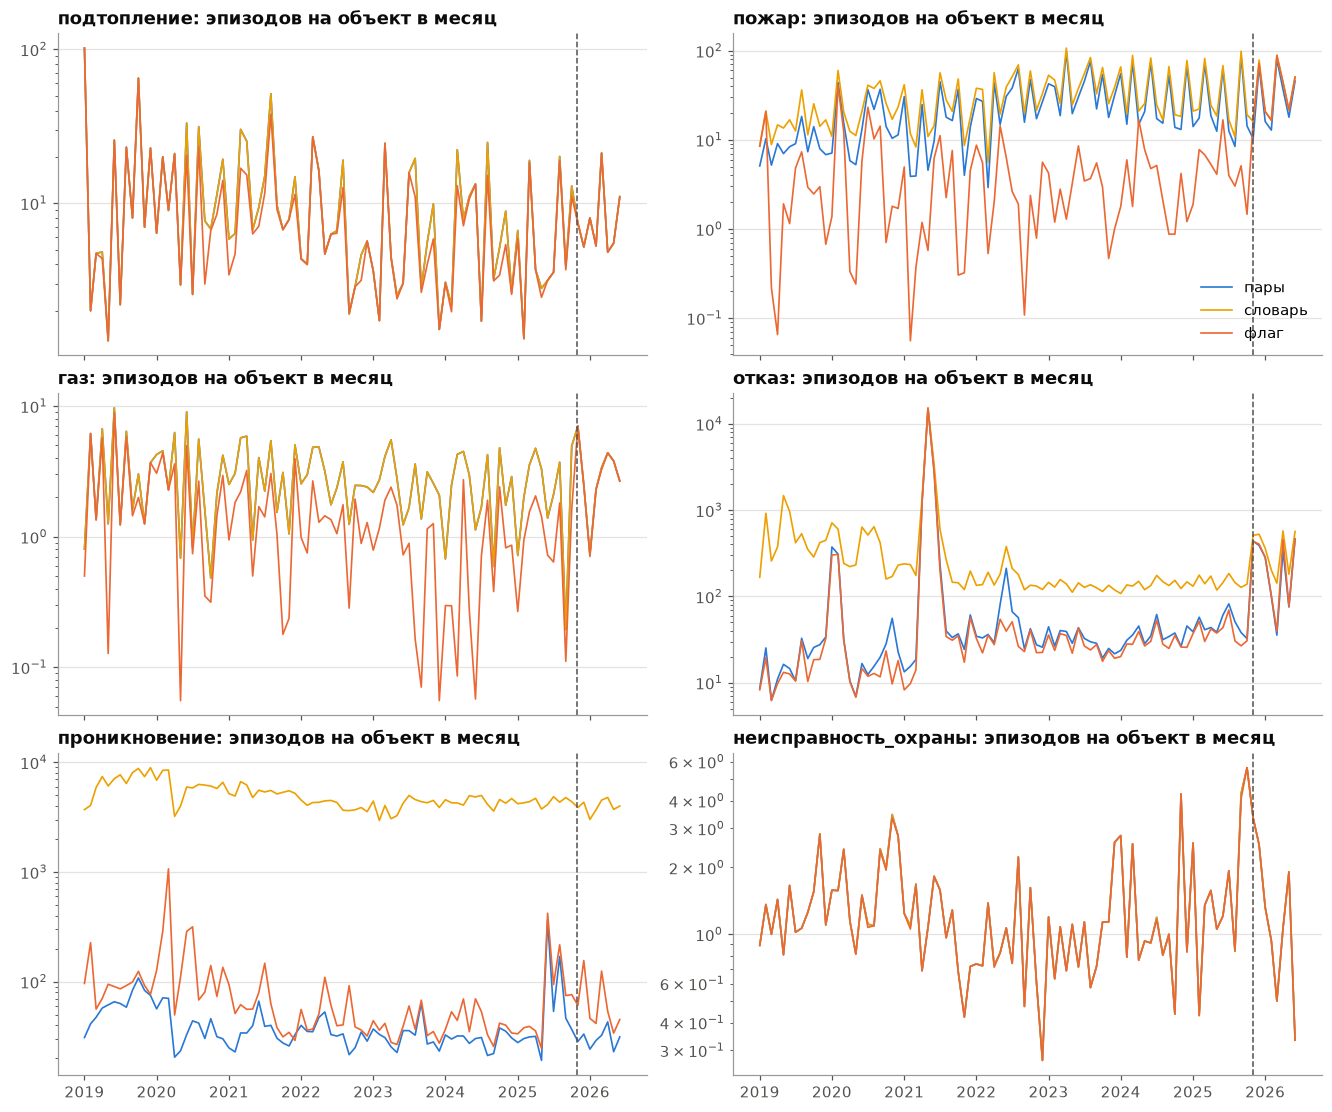

класс                                         подтопление  пожар   газ  отказ  проникновение  неисправность_охраны
пары    после смены / год назад                     1.530  1.030 1.260  5.550          0.460                 1.280
        контроль: год назад / два года назад        0.690  0.820 1.060  1.470          2.320                 1.010
словарь после смены / год назад                     1.530  1.010 1.260  2.450          0.930                 1.280
        контроль: год назад / два года назад        0.690  0.810 1.060  1.140          0.980                 1.010
флаг    после смены / год назад                     1.720  6.790 2.560  6.990          0.900                 1.280
        контроль: год назад / два года назад        0.760  1.130 1.780  1.410          1.750                 1.010

In [13]:
obj_days = (daily_channel.join(F.broadcast(channels.select("ид_канала_данных", "ид_объект")), "ид_канала_данных")
            .groupBy("ид_объект", "день").agg(F.sum("количество_событий").alias("записей")).toPandas())
obj_days["день"] = pd.to_datetime(obj_days["день"])
active = obj_days.groupby(obj_days["день"].dt.to_period("M").dt.to_timestamp())["ид_объект"].nunique()


def monthly(eps):
    m = eps.groupBy(F.trunc("начало", "month").alias("месяц"), "класс").count().toPandas()
    m["месяц"] = pd.to_datetime(m["месяц"])
    return m.pivot(index="месяц", columns="класс", values="count").fillna(0).div(active, axis=0)


MON = {s: monthly(e) for s, e in EPS.items()}
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for ax, c in zip(axes.flat, ep.TARGET_CLASSES):
    for s, m in MON.items():
        if c in m:
            ax.plot(m.index, m[c], label=s, color=SOURCE_COLOR[s], lw=1.1)
    ax.axvline(FLAG_CHANGE, color=INK2, ls="--", lw=1)
    ax.set_title(f"{c}: эпизодов на объект в месяц")
    ax.set_yscale("log")
axes[0, 1].legend()
plt.show()


def ratio(m, a0, a1, b0, b1):
    """Среднее за [b0, b1] / среднее за [a0, a1] по месяцам."""
    return m.loc[b0:b1].mean() / m.loc[a0:a1].mean()


last = END.to_period("M").to_timestamp()
first_after = FLAG_CHANGE.to_period("M").to_timestamp()
yr = pd.DateOffset(years=1)
rows = {}
for s, m in MON.items():
    rows[(s, "после смены / год назад")] = ratio(m, first_after - yr, last - yr, first_after, last)
    rows[(s, "контроль: год назад / два года назад")] = ratio(m, first_after - 2 * yr, last - 2 * yr,
                                                               first_after - yr, last - yr)
stab = pd.DataFrame(rows).T[ep.TARGET_CLASSES]
display(stab.round(2))

**Результат по эпизодам.** Сравниваем среднее число эпизодов на объект в месяц с ноября 2025 по июнь 2026
с теми же месяцами годом раньше, а для контроля – год назад с двумя годами назад (обычная межгодовая
изменчивость). У флага пожары после смены выросли в 6,79 раза (контроль 1,13), газ – в 2,56 (контроль 1,78).
У пар и словаря пожар почти не изменился: 1,03 и 1,01. Но у отказа растут все три источника: пары в 5,55 раза
(контроль 1,47), словарь в 2,45, флаг в 6,99. Подтопление выросло во всех источниках одинаково (1,53-1,72) –
это свойство данных, а не разметки. Неисправность охраны во всех источниках одна и та же (1,28 при контроле
1,01): эту пару система помечает флагом всегда.

Число эпизодов чувствительно к «болтливым» каналам: один датчик, который дребезжит весь день, дает сотни
эпизодов. Для целевой важнее другое – доля объекто-суток, в которые начался хотя бы один эпизод класса.
Повторим сравнение в этой мере.

In [14]:
T_GRID = [0, 10, 30, 60, 120, 300, 600, 1800]


def daily_hits(eps):
    """Объект × сутки начала × класс: число эпизодов не короче каждого порога из T_GRID
    (незакрытый эпизод считается длинным)."""
    dur = F.coalesce(F.col("длительность_с"), F.lit(10**9))
    h = (eps.groupBy("ид_объект", F.to_date("начало").alias("день"), "класс")
         .agg(*[F.sum((dur >= t).cast("int")).alias(f"от_{t}_с") for t in T_GRID]).toPandas())
    h["день"] = pd.to_datetime(h["день"])
    return h


HITS = {s: daily_hits(e) for s, e in EPS.items()}
active_days = obj_days[obj_days["записей"] > 0].groupby(obj_days["день"].dt.to_period("M").dt.to_timestamp()).size()
rows = {}
for s, h in HITS.items():
    m = (h[h["от_0_с"] > 0].groupby([h["день"].dt.to_period("M").dt.to_timestamp(), "класс"]).size()
         .unstack("класс").fillna(0).div(active_days, axis=0).fillna(0))
    rows[(s, "после смены / год назад")] = ratio(m, first_after - yr, last - yr, first_after, last)
    rows[(s, "контроль: год назад / два года назад")] = ratio(m, first_after - 2 * yr, last - 2 * yr,
                                                               first_after - yr, last - yr)
stab_days = pd.DataFrame(rows).T.reindex(columns=ep.TARGET_CLASSES)
display(stab_days.round(2))

класс                                         подтопление  пожар   газ  отказ  проникновение  неисправность_охраны
пары    после смены / год назад                     1.430  1.370 1.040  1.210          0.960                 1.090
        контроль: год назад / два года назад        0.820  1.090 0.890  0.940          0.960                 0.910
словарь после смены / год назад                     1.430  1.340 1.040  1.080          0.960                 1.090
        контроль: год назад / два года назад        0.820  1.090 0.890  0.960          1.020                 0.910
флаг    после смены / год назад                     1.480  2.110 1.730  1.290          1.020                 1.090
        контроль: год назад / два года назад        0.800  1.170 0.850  0.930          0.980                 0.910

**Результат по объекто-суткам.** В этой мере картина спокойнее. Пожар: у флага рост в 2,11 раза (контроль
1,17), у пар 1,37 (контроль 1,09), у словаря 1,34. Газ: флаг 1,73 против 1,04 у пар. Отказ: пары 1,21
(контроль 0,94), словарь 1,08, флаг 1,29. Подтопление: 1,43-1,48 у всех, неисправность охраны: 1,09
(контроль 0,91). Значит, флаг сильнее всего ломает именно пожар и газ – то, что раньше подавлялось днем.

Остается рост отказа у пар. Разберем, какие пары его дают.

Какие пары «отказа» дают рост после смены разметки – сравним среднемесячное
число записей пары после смены с теми же месяцами годом раньше.

In [15]:
fp = fh[is_key(fh, [p for p in PAIRS if ep.state_class(*p) == "отказ"])]
fpm = fp.groupby(["тип_датчика", "состояние", "месяц"])["количество_событий"].sum().unstack(["тип_датчика", "состояние"]).fillna(0)
drv = pd.DataFrame({"записей_в_месяц_год_назад": fpm.loc[first_after - yr:last - yr].mean(),
                    "записей_в_месяц_после_смены": fpm.loc[first_after:last].mean()})
drv["прирост"] = drv["записей_в_месяц_после_смены"] - drv["записей_в_месяц_год_назад"]
display(drv.sort_values("прирост", ascending=False).round(0).head(8))

записей_в_месяц_год_назад  записей_в_месяц_после_смены   прирост
тип_датчика           состояние                                                                      
Датчик дыма           Неисправен                       757.000                    6 970.000 6 213.000
Датчик температуры    Неисправен                         2.000                    4 443.000 4 442.000
Газовый датчик        Неисправен                         8.000                    3 809.000 3 801.000
Состояние насоса      Неисправен                     1 098.000                    1 888.000   790.000
                      Обесточен                      1 046.000                    1 758.000   712.000
Состояние вентилятора Неисправен                     1 056.000                    1 339.000   283.000
                      Обесточен                      1 055.000                    1 323.000   268.000
Датчик температуры    Не определено                     68.000                      138.000    71.000

**Результат.** Рост отказа дают не пары со сменой флага, а новые потоки состояний: «Неисправен» датчиков
температуры – в среднем 2 записи в месяц годом раньше и 4 443 после смены, газовых датчиков – 8 и 3 809,
дымовых – 757 и 6 970. То есть в конце октября 2025 года в СМВУ поменялась не только разметка флага, но и то,
какие состояния пишут датчики: температурные и газовые стали массово сообщать о неисправности. Ни один источник,
построенный по журналу, от этого не защищен: это изменение самих данных. На уровне объекто-суток эффект
умеренный (+21 % против −6 % в контроле), но период после смены нужно помечать: для этого в целевой таблице
есть столбец `эпоха_флага`, а тест после смены будет показан отдельной строкой (раздел 9).

**Вывод раздела 1.**

Выбираем источник **«пары»**: словарь состояний, из которого исключены пары, которые сама СМВУ ночью не считает
тревогой. Флаг отвергнут: он зависит от часа суток и сменил правило в конце октября 2025 года (пожары по флагу
после смены ×2,11 объекто-суток при контроле ×1,17, эпизодов ×6,79). Чистый словарь отвергнут: он считает
отказом ежедневные переключения фазы (992 828 записей без единого флага) и проникновением каждое движение
(28 млн эпизодов). Пары с этими завышениями не страдают и не зависят от флага после 2025-10. Предсказуемость
трех вариантов сравнивается в разделе 8.

## 2. Из записей в эпизоды

Почему единица – эпизод, а не запись. Датчик в тревоге часто пишет не одну запись, а цепочку, иногда несколько
записей в одну секунду: насос сообщает «Неисправен», «Затоплен», «Обесточен» подряд. Если считать записи,
один инцидент превратится в несколько, а болтливый датчик будет весить больше спокойного.
Проверим, насколько это часто в выбранном источнике.

In [16]:
E = EPS["пары"]
pairs_sdf = spark.createDataFrame(pairs[["тип_датчика", "состояние"]])
state_runs = spark.read.parquet(str(EDA_DIR / "state_runs.parquet"))  # смены состояния со временем до следующей
alarm_recs = (state_runs.join(F.broadcast(channels.select("ид_канала_данных", "тип_датчика")), "ид_канала_данных")
              .join(F.broadcast(pairs_sdf), ["тип_датчика", "состояние"]))
same_sec = alarm_recs.agg(F.count("*").alias("записей"),
                          F.sum((F.col("секунд_до_следующего") == 0).cast("int")).alias("следующая_в_ту_же_секунду"),
                          ).toPandas().iloc[0]
print(f"тревожных записей: {n(same_sec['записей'])}, следующая запись канала в ту же секунду: "
      f"{same_sec['следующая_в_ту_же_секунду'] / same_sec['записей']:.1%}")
rec_bins = (E.withColumn("записей_в_эпизоде", F.when(F.col("записей") >= 5, "5+").otherwise(F.col("записей").cast("string")))
            .groupBy("записей_в_эпизоде").agg(F.count("*").alias("эпизодов"), F.sum("записей").alias("записей"))
            .toPandas().set_index("записей_в_эпизоде").sort_index())
rec_bins["доля_эпизодов"] = rec_bins["эпизодов"] / rec_bins["эпизодов"].sum()
display(rec_bins)
print(f"записей в эпизодах: {n(rec_bins['записей'].sum())}, эпизодов: {n(rec_bins['эпизодов'].sum())}, "
      f"в среднем {rec_bins['записей'].sum() / rec_bins['эпизодов'].sum():.2f} записи на эпизод")

тревожных записей: 2 279 819, следующая запись канала в ту же секунду: 13.6%


,эпизодов,записей,доля_эпизодов
записей_в_эпизоде,,,
1,1819332,1819332,0.899
2,153830,307660,0.076
3,48670,146010,0.024
4,911,3644,0.000
5+,490,3175,0.000


записей в эпизодах: 2 279 821, эпизодов: 2 023 233, в среднем 1.13 записи на эпизод


**Результат.** Из 2 279 819 тревожных записей у 13,6 % следующая запись того же канала пришла в ту же секунду.
89,9 % эпизодов состоят из одной записи, 7,6 % – из двух, 2,4 % – из трех; в среднем 1,13 записи на эпизод.
Склейка в эпизоды почти не меняет объем, но убирает двойной счет цепочек, и число эпизодов канала становится
числом срабатываний, а не числом строк журнала.

Второй вопрос – какой класс у цепочки. Правило: самый важный по приоритету подтопление → пожар → газ → отказ →
проникновение. Логика: если насос сообщил «Неисправен», а через мгновение «Затоплен», первопричина для
диспетчера – вода, а неисправность насоса ее следствие. Сколько эпизодов меняют класс по этому правилу:

In [17]:
changed = (E.filter(F.col("класс") != F.col("первый_класс")).groupBy("первый_класс", "класс").count()
           .toPandas().sort_values("count", ascending=False))
display(changed)
total_e = int(ep_counts["пары"].sum())
print(f"эпизодов, где итоговый класс не совпадает с классом первой записи: {n(changed['count'].sum())} "
      f"из {n(total_e)} ({changed['count'].sum() / total_e:.2%})")
ex = (E.filter((F.col("первый_класс") == "отказ") & (F.col("класс") == "подтопление") & (F.col("записей") >= 3))
      .orderBy("начало").limit(1).toPandas().iloc[0])
lo, hi = ex["начало"] - pd.Timedelta(minutes=1), (ex["конец"] if pd.notna(ex["конец"]) else ex["начало"]) + pd.Timedelta(minutes=1)
display(events.filter((F.col("год") == lo.year) & (F.col("месяц") == lo.month)
                      & (F.col("ид_канала_данных") == int(ex["ид_канала_данных"]))
                      & F.col("дата_время").between(lo, hi))
        .select("дата_время", "ид_события", "состояние", "тревожное").orderBy("дата_время", "ид_события").toPandas())
print(f"пример: канал {ex['ид_канала_данных']} ({ex['тип_датчика']}), объект {ex['ид_объект']}, "
      f"эпизод {ex['начало']} … {ex['конец']}, класс «{ex['класс']}»")

,первый_класс,класс,count
4,отказ,подтопление,60867
1,откачка,подтопление,260
2,откачка,отказ,228
3,отказ,пожар,119
6,проникновение,отказ,67
0,вывод_из_работы,пожар,63
5,вывод_из_работы,отказ,8
7,отказ,газ,1


эпизодов, где итоговый класс не совпадает с классом первой записи: 61 613 из 2 023 233 (3.05%)


,дата_время,ид_события,состояние,тревожное
0,2019-01-02 04:33:02,1385358086,Неисправен,True
1,2019-01-02 04:33:02,1385358087,Затоплен,True
2,2019-01-02 04:33:02,1385358088,Норма,False
3,2019-01-02 04:33:02,1385358089,Выключен,False
4,2019-01-02 04:33:08,1385358122,Неисправен,True
5,2019-01-02 04:33:08,1385358123,Обесточен,True
6,2019-01-02 04:33:08,1385358124,Затоплен,True
7,2019-01-02 04:34:32,1385358281,Норма,False
8,2019-01-02 04:34:32,1385358282,Выключен,False


пример: канал 115797 (Состояние насоса), объект 3902, эпизод 2019-01-02 04:33:08 … 2019-01-02 04:34:32, класс «подтопление»


**Результат.** Класс по приоритету отличается от класса первой записи у 61 613 эпизодов из 2 023 233 (3,05 %),
почти все – «отказ → подтопление» (60 867): насос сначала сообщает о неисправности, а в той же цепочке –
о затоплении. Пример выше: насос на объекте 3902 в 04:33:02 сообщил «Неисправен» и «Затоплен» и в ту же секунду
вернулся в «Норму» (эпизод 0 с), в 04:33:08 – «Неисправен», «Обесточен», «Затоплен», и норма вернулась через
84 с. Второй эпизод – это подтопление, а не отказ насоса.

**Вывод.** Единица – эпизод канала; класс эпизода – самый важный класс в цепочке.

## 3. Дребезг

Не каждый эпизод – событие. Датчик на границе срабатывания «дребезжит»: тревога – норма – тревога через
секунды. Гипотеза: очень короткие эпизоды – в основном дребезг, а не инцидент. Если это так, короткие эпизоды
должны (а) чаще повторяться на том же канале в течение часа и (б) сильнее концентрироваться на немногих
«болтливых» каналах. Сначала распределение длительностей по классам.

In [18]:
BINS = [(0, 0, "0 с"), (1, 9, "1-9 с"), (10, 29, "10-29 с"), (30, 59, "30-59 с"), (60, 119, "1-2 мин"),
        (120, 599, "2-10 мин"), (600, 3599, "10-60 мин"), (3600, 86399, "1-24 ч"), (86400, None, "сутки+")]
BIN_ORDER = [b[2] for b in BINS] + ["не закрыт"]


def dur_bin(col="длительность_с"):
    e = F.when(F.col(col).isNull(), "не закрыт")
    for lo_, hi_, name in BINS:
        e = e.when(F.col(col) >= lo_ if hi_ is None else F.col(col).between(lo_, hi_), name)
    return e


w_ch = Window.partitionBy("ид_канала_данных").orderBy("начало")
Eb = (E.withColumn("корзина", dur_bin())
      .withColumn("пауза_до_следующего_с", F.lead("начало").over(w_ch).cast("long")
                  - F.coalesce("конец", "начало").cast("long"))
      .withColumn("повтор_в_течение_часа", F.coalesce(F.col("пауза_до_следующего_с") <= 3600, F.lit(False))))
dist = Eb.groupBy("корзина", "класс").count().toPandas().pivot(index="корзина", columns="класс", values="count")
dist = dist.reindex(index=BIN_ORDER, columns=ep.PRIORITY).fillna(0)
display((dist / dist.sum()).round(3))
print("эпизодов по классам:", {c: n(v) for c, v in dist.sum().items()})
print(f"доля эпизодов короче 60 с: {dist.loc[BIN_ORDER[:4]].sum().sum() / dist.sum().sum():.1%}")

класс,подтопление,пожар,газ,отказ,проникновение,неисправность_охраны,откачка,вывод_из_работы
корзина,,,,,,,,
0 с,0.096,0.001,0.007,0.033,0.047,0.007,0.001,0.001
1-9 с,0.233,0.029,0.075,0.133,0.296,0.027,0.198,0.033
10-29 с,0.332,0.145,0.337,0.138,0.226,0.124,0.157,0.025
30-59 с,0.194,0.110,0.370,0.169,0.116,0.115,0.467,0.016
1-2 мин,0.052,0.146,0.153,0.201,0.089,0.112,0.025,0.035
2-10 мин,0.038,0.343,0.023,0.260,0.133,0.351,0.054,0.338
10-60 мин,0.034,0.183,0.013,0.056,0.068,0.179,0.050,0.292
1-24 ч,0.020,0.042,0.009,0.008,0.025,0.077,0.047,0.175
сутки+,0.001,0.002,0.013,0.001,0.000,0.007,0.001,0.078


эпизодов по классам: {'подтопление': '65 336', 'пожар': '167 470', 'газ': '17 812', 'отказ': '1 442 658', 'проникновение': '249 014', 'неисправность_охраны': '8 117', 'откачка': '69 450', 'вывод_из_работы': '3 376'}
доля эпизодов короче 60 с: 51.0%


,эпизодов,доля_повторов_за_час,каналов,доля_топ_1%_каналов
корзина,,,,
0 с,65666,0.860,1988,0.680
1-9 с,301616,0.774,3500,0.500
10-29 с,319344,0.839,5137,0.366
30-59 с,344495,0.861,5192,0.505
1-2 мин,344777,0.904,5693,0.573
2-10 мин,476700,0.844,6140,0.599
10-60 мин,136922,0.654,6014,0.388
1-24 ч,30600,0.461,4068,0.218
сутки+,2807,0.337,1390,0.073


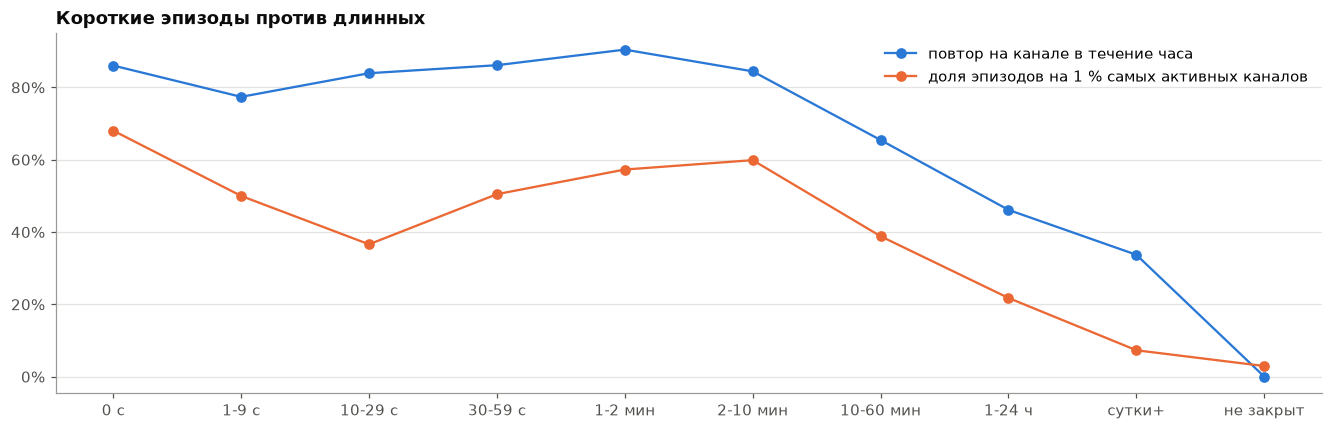

In [19]:
per_bin = (Eb.groupBy("корзина", "ид_канала_данных")
           .agg(F.count("*").alias("эпизодов"), F.sum(F.col("повтор_в_течение_часа").cast("int")).alias("повторов"))
           .toPandas())


def top1_share(g):
    s = g["эпизодов"].sort_values(ascending=False)
    return s.iloc[:max(1, int(np.ceil(0.01 * len(s))))].sum() / s.sum()


flap = pd.DataFrame({
    "эпизодов": per_bin.groupby("корзина")["эпизодов"].sum(),
    "доля_повторов_за_час": per_bin.groupby("корзина")["повторов"].sum() / per_bin.groupby("корзина")["эпизодов"].sum(),
    "каналов": per_bin.groupby("корзина")["ид_канала_данных"].nunique(),
    "доля_топ_1%_каналов": per_bin.groupby("корзина")[["эпизодов"]].apply(top1_share),
}).reindex(BIN_ORDER)
display(flap)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(flap.index, flap["доля_повторов_за_час"], marker="o", label="повтор на канале в течение часа")
ax.plot(flap.index, flap["доля_топ_1%_каналов"], marker="o", label="доля эпизодов на 1 % самых активных каналов")
ax.set_title("Короткие эпизоды против длинных")
pct(ax)
ax.legend()
plt.show()

**Результат.** Эпизоды короче минуты – 51,0 % всех. Гипотеза подтвердилась только частично:
- эпизоды длительностью от секунды до 10 минут повторяются на том же канале в течение часа одинаково часто –
  от 77 % до 90 %; короткие не выделяются. Заметно реже повторяются только эпизоды дольше 10 минут (65 %),
  дольше часа (46 %) и дольше суток (34 %);
- по концентрации выделяются только эпизоды длительностью 0 с: 68 % из них дают 1 % самых активных каналов
  (для 1-9 с – 50 %, для 10-29 с – 37 %, для 1-2 мин – 57 %).

Значит, естественной границы «дребезг / событие» в диапазоне 30-120 с данные не дают. Явный артефакт – эпизоды
0 с (состояние вернулось в ту же секунду). Следующая заметная граница – 10 минут, после которой эпизоды реже
повторяются.

Порог дребезга – не только вопрос «что считать событием», но и сколько положительных объекто-суток мы
теряем. Посчитаем число объекто-суток, в которые начался хотя бы один эпизод класса длиннее порога,
для порогов от 0 до 5 минут (незакрытый эпизод длинный по определению).

In [20]:
sens = pd.DataFrame({t: (HITS["пары"][f"от_{t}_с"] > 0).groupby(HITS["пары"]["класс"]).sum() for t in T_GRID})
sens.columns = [f"порог {t} с" for t in T_GRID]
sens = sens.reindex(ep.PRIORITY).fillna(0).astype("int64")
display(sens)
display((sens.div(sens.iloc[:, 0], axis=0)).round(3))

,порог 0 с,порог 10 с,порог 30 с,порог 60 с,порог 120 с,порог 300 с,порог 600 с,порог 1800 с
класс,,,,,,,,
подтопление,3798,2352,1734,1480,1261,1051,875,637
пожар,3290,3141,2886,2682,2312,2049,1802,1299
газ,974,840,776,536,257,179,158,124
отказ,15418,8202,6624,5780,4959,4172,3575,2463
проникновение,25131,21743,19971,17681,15257,12048,9350,5807
неисправность_охраны,4584,4514,4145,3699,3323,2373,1692,1022
откачка,4171,3686,3291,1569,1274,799,639,519
вывод_из_работы,344,292,257,236,223,202,191,172


,порог 0 с,порог 10 с,порог 30 с,порог 60 с,порог 120 с,порог 300 с,порог 600 с,порог 1800 с
класс,,,,,,,,
подтопление,1.000,0.619,0.457,0.390,0.332,0.277,0.230,0.168
пожар,1.000,0.955,0.877,0.815,0.703,0.623,0.548,0.395
газ,1.000,0.862,0.797,0.550,0.264,0.184,0.162,0.127
отказ,1.000,0.532,0.430,0.375,0.322,0.271,0.232,0.160
проникновение,1.000,0.865,0.795,0.704,0.607,0.479,0.372,0.231
неисправность_охраны,1.000,0.985,0.904,0.807,0.725,0.518,0.369,0.223
откачка,1.000,0.884,0.789,0.376,0.305,0.192,0.153,0.124
вывод_из_работы,1.000,0.849,0.747,0.686,0.648,0.587,0.555,0.500


**Результат.** Порог сильно влияет на объем: при 60 с остается 37,5 % положительных объекто-суток отказа
от «любой длительности», 39,0 % подтопления, 55,0 % газа, 81,5 % пожара и 80,7 % неисправности охраны;
при 10 минутах – 23,2 %, 23,0 %, 16,2 %, 54,8 % и 36,9 %.

**Выбор: 60 секунд.** Обоснование не из формы распределения (ее нет), а из смысла: тревога, которая
закончилась меньше чем за минуту, не требует от диспетчера действий, а эпизоды 0 с – явный артефакт.
Порог 10 минут отрезал бы больше половины подтоплений и газа без признаков того, что это дребезг
(они повторяются так же, как 1-2-минутные). Раздел 8 проверяет, не хуже ли прогнозируется цель при порогах
0 и 600 с. Незакрытый эпизод считается длинным.

In [21]:
T_FLAP = 60

## 4. Работы бригад и ложные отказы

Часть тревог порождают не аварии, а люди: бригада открывает люк, отключает насос на обслуживание, пылит
у дымового извещателя. Раздел 1.2 уже показал, что СМВУ до смены разметки (2025-10-29) по будням днем часто не помечала флагом тревоги
в рабочие часы. Посмотрим на сами эпизоды «отказ» (длиннее порога дребезга): когда они начинаются.

эпизодов «отказ» не короче 60 с: 759 653
начались в рабочее время (пн-пт 8:00-17:59): 33.7%; доля рабочего времени в неделе: 29.8%


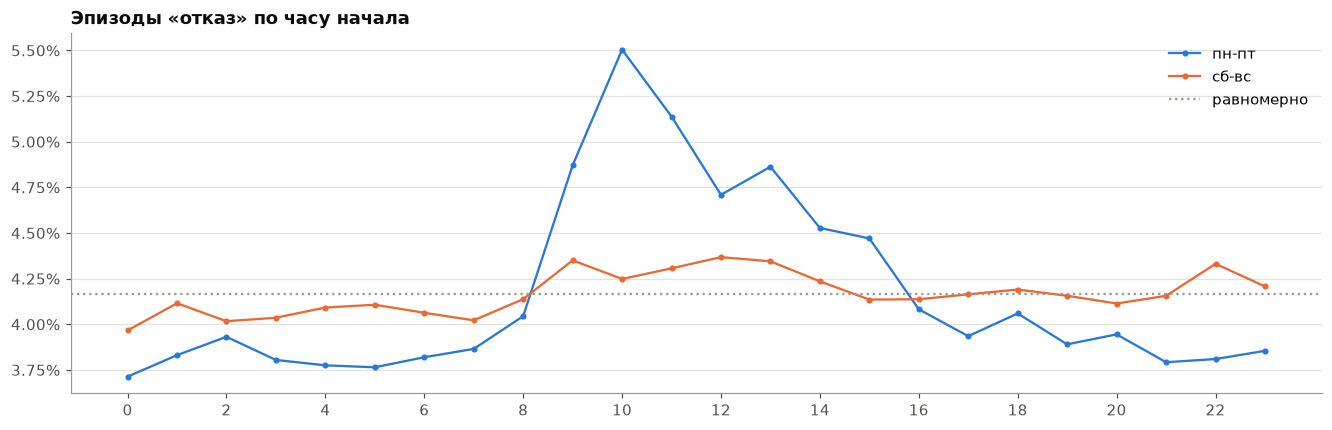

доля эпизодов «отказ» без единой записи с флагом до смены разметки: {'остальное время': '1.6%', 'рабочее время': '4.9%'}


In [22]:
nf = (F.col("длительность_с").isNull() | (F.col("длительность_с") >= T_FLAP))
faults = (E.filter(nf & (F.col("класс") == "отказ"))
          .select("ид_объект", "ид_канала_данных", "тип_датчика", "начало", "доля_флага").toPandas())
faults["час"] = faults["начало"].dt.hour
faults["рабочий_день"] = faults["начало"].dt.dayofweek < 5
faults["рабочее_время"] = faults["рабочий_день"] & faults["час"].between(8, 17)
WORK_SHARE_OF_WEEK = 5 * 10 / 168
print(f"эпизодов «отказ» не короче {T_FLAP} с: {n(len(faults))}")
print(f"начались в рабочее время (пн-пт 8:00-17:59): {faults['рабочее_время'].mean():.1%}; "
      f"доля рабочего времени в неделе: {WORK_SHARE_OF_WEEK:.1%}")
fig, ax = plt.subplots(figsize=(12, 3.8))
for wd, label in [(True, "пн-пт"), (False, "сб-вс")]:
    x = faults[faults["рабочий_день"] == wd]["час"].value_counts(normalize=True).sort_index()
    ax.plot(x.index, x.values, marker="o", ms=3, label=label)
ax.axhline(1 / 24, color=GREY, ls=":", label="равномерно")
ax.set_title("Эпизоды «отказ» по часу начала")
ax.set_xticks(range(0, 24, 2))
pct(ax)
ax.legend()
plt.show()
pre = faults[faults["начало"] < STABLE_UNTIL]
sup = pre.groupby("рабочее_время")["доля_флага"].apply(lambda s: (s == 0).mean())
print("доля эпизодов «отказ» без единой записи с флагом до смены разметки:",
      {("рабочее время" if k else "остальное время"): f"{v:.1%}" for k, v in sup.items()})

**Результат.** Эпизодов «отказ» длиннее минуты – 759 653. В рабочее время (пн-пт 8:00-17:59) начались 33,7 %
при доле рабочего времени в неделе 29,8 %: перекос есть, но небольшой. Без единой записи с флагом до смены
разметки было лишь 4,9 % отказов в рабочее время и 1,6 % в остальное: подавление флага почти не касается
отказов.

Прямых данных о работах (графика, заявок, нарядов) нет. Косвенный след работ – открытие двери или люка
на том же объекте незадолго до отказа. Проверка: для каждого эпизода «отказ» смотрим, открывались ли
«КД Дверь» или «КД Люк» на этом объекте в пределах 3 часов до начала (по часам: тот же час и три
предыдущих). Чтобы понять, много это или мало, сравниваем с долей всех активных объекто-часов, у которых
в том же окне было открытие.

In [23]:
DOORS = ["КД Дверь", "КД Люк"]
openings = (EPS["словарь"].filter(F.col("тип_датчика").isin(DOORS) & (F.col("класс") == "проникновение"))
            .select("ид_объект", F.date_trunc("hour", "начало").alias("час")).distinct())
cover = (openings.select("ид_объект", F.explode(F.sequence(F.col("час"), F.col("час") + F.expr("INTERVAL 3 HOURS"),
                                                           F.expr("INTERVAL 1 HOUR"))).alias("час"))
         .distinct().withColumn("открытие_за_3_ч", F.lit(True)))
active_hours = int((obj_days["записей"] > 0).sum()) * 24
cover_pd = cover.toPandas()
cover_pd["день"] = cover_pd["час"].dt.floor("D")
act = obj_days.loc[obj_days["записей"] > 0, ["ид_объект", "день"]]
cover_pd = cover_pd.merge(act, on=["ид_объект", "день"])  # только активные объекто-сутки
cover_pd["рабочее_время"] = (cover_pd["час"].dt.dayofweek < 5) & cover_pd["час"].dt.hour.between(8, 17)
act_wd = int((act["день"].dt.dayofweek < 5).sum())
work_hours, other_hours = act_wd * 10, len(act) * 24 - act_wd * 10
fault_open = (E.filter(nf & (F.col("класс") == "отказ"))
              .select("ид_объект", "начало", F.date_trunc("hour", "начало").alias("час"))
              .join(cover, ["ид_объект", "час"], "left")
              .select("ид_объект", "начало", F.coalesce("открытие_за_3_ч", F.lit(False)).alias("открытие_за_3_ч"))
              .toPandas())
faults = faults.merge(fault_open.drop_duplicates(["ид_объект", "начало"]), on=["ид_объект", "начало"], how="left")
base = pd.Series({True: cover_pd["рабочее_время"].sum() / work_hours,
                  False: (~cover_pd["рабочее_время"]).sum() / other_hours})
print(f"доля активных объекто-часов с открытием двери/люка за 3 ч: {len(cover_pd) / active_hours:.1%}")
fo = faults.groupby("рабочее_время")["открытие_за_3_ч"].agg(["mean", "size"])
fo["доля_объекто_часов_с_открытием"] = base
display(fo.rename(index={True: "рабочее время", False: "остальное время"},
                  columns={"mean": "доля_отказов_с_открытием", "size": "эпизодов"}))
print(f"все эпизоды «отказ»: с открытием за 3 ч {faults['открытие_за_3_ч'].mean():.1%}")
display(faults.groupby("тип_датчика")["открытие_за_3_ч"].agg(["mean", "size"])
        .sort_values("size", ascending=False).head(8))

доля активных объекто-часов с открытием двери/люка за 3 ч: 19.2%


,доля_отказов_с_открытием,эпизодов,доля_объекто_часов_с_открытием
рабочее_время,,,
остальное время,0.089,503787,0.104
рабочее время,0.423,255866,0.385


все эпизоды «отказ»: с открытием за 3 ч 20.1%


,mean,size
тип_датчика,,
Датчик дыма,0.203,715389
Состояние вентилятора,0.124,20111
Состояние насоса,0.176,12150
Состояние фазы,0.052,4089
Газовый датчик,0.022,2561
Датчик температуры,0.736,2405
ИБП,0.402,2101
Датчик движения,0.702,583


**Результат.** Открытие двери или люка за 3 часа до отказа было у 42,3 % отказов в рабочее время, но и у
38,5 % всех активных объекто-часов рабочего времени. Вне рабочего времени – 8,9 % против 10,4 % фона.
Всего у 20,1 % отказов при фоне 19,2 %. Отказы не связаны с открытиями сильнее, чем случайный момент в то же
время суток. Исключения – «Датчик температуры» (73,6 % из 2 405 эпизодов) и ИБП (40,2 % из 2 101): их отказы
похожи на работы. Основную массу отказов (715 389 эпизодов из 759 653) дают «Неисправен» дымовых датчиков.

Отказы – не единственный класс, на который могут влиять работы. Сравним все классы: доля эпизодов,
начавшихся в рабочее время, и доля эпизодов, в которых до смены разметки не было ни одной записи с флагом
(СМВУ не сочла их тревогой).

In [24]:
wt = ((F.dayofweek("начало").between(2, 6)) & F.hour("начало").between(8, 17)).cast("int")
cls_work = (E.filter(nf).groupBy("класс")
            .agg(F.count("*").alias("эпизодов"), F.avg(wt).alias("доля_в_рабочее_время"),
                 F.avg(F.when(F.col("начало") < F.lit(STABLE_UNTIL), (F.col("доля_флага") == 0).cast("int")))
                 .alias("доля_без_флага_до_смены"),
                 F.avg(F.when((F.col("начало") < F.lit(STABLE_UNTIL)) & (wt == 1), (F.col("доля_флага") == 0).cast("int")))
                 .alias("доля_без_флага_до_смены_в_рабочее_время"))
            .toPandas().set_index("класс").reindex(ep.PRIORITY))
display(cls_work)

,эпизодов,доля_в_рабочее_время,доля_без_флага_до_смены,доля_без_флага_до_смены_в_рабочее_время
класс,,,,
подтопление,9489,0.834,0.130,0.155
пожар,119715,0.969,0.893,0.912
газ,3768,0.946,0.540,0.549
отказ,759653,0.337,0.027,0.049
проникновение,78225,0.839,0.043,0.041
неисправность_охраны,5897,0.508,0.006,0.012
откачка,12242,0.315,0.002,0.006
вывод_из_работы,3123,0.795,0.264,0.310


**Результат.** Картина по классам очень разная. Пожар: 96,9 % эпизодов начались в рабочее время, и до смены
разметки 89,3 % из них система не пометила флагом ни разу. Газ: 94,6 % и 54,0 %. Подтопление: 83,4 % и 13,0 %.
Проникновение: 83,9 % в рабочее время. А отказ – 33,7 % и 2,7 %. Неисправность охраны – посередине: 50,8 %
в рабочее время, и флагом система помечает ее почти всегда (без флага 0,6 %).

**Вывод.** Срабатывания дымовых и газовых датчиков происходят почти только в рабочее время, и сама СМВУ не
считала тревогой большинство из них. Наиболее вероятное объяснение – работы (пыль, сварка, проверки
газоанализаторов), но без графика работ и журнала ОДС это гипотеза, а не факт. Для газа ее удается проверить
по графику плановых работ аппаратуры контроля метана – это сделано в разделе 6.4. Отказы, наоборот, распределены
по суткам почти равномерно и с открытиями не связаны.

**Решение.** Не удаляем такие эпизоды из целевой: после смены разметки система помечает их тревогой, диспетчер
их получает, и отделить работы по данным надежно нельзя. Контекст (рабочее время, открытия дверей и люков)
пойдет в признаки. Вариант «вне рабочего времени» для пожара, газа и подтопления и вариант «отказ вне работ»
(без открытия за 3 часа) проверяем на предсказуемость в разделе 8. Закрыли бы вопрос график работ бригад,
наряды-допуски и журнал ОДС с отметкой «ложное срабатывание».

## 5. Потеря связи

Отдельный класс, который прямо не назван в ТЗ, но важен диспетчеру: объект перестает отвечать. В журнале это
видно как пачка «Неопределен»: в одну минуту многие каналы объекта одновременно уходят в неопределенное
состояние. Одиночный канал в «Неопределен» – скорее сбой датчика, чем потеря связи. Посмотрим, какую долю
каналов объекта охватывают минуты с «Неопределен».

In [25]:
bursts = spark.read.parquet(str(EDA_DIR / "undefined_bursts.parquet")).toPandas().dropna(subset=["ид_объект"])
bursts["ид_объект"] = bursts["ид_объект"].astype("int64")
n_obj = channels_pd.groupby("ид_объект")["ид_канала_данных"].nunique().rename("каналов_объекта")
bursts = bursts.join(n_obj, on="ид_объект")
bursts["доля_каналов"] = bursts["каналов_в_неопределен"] / bursts["каналов_объекта"]
size_tab = pd.DataFrame({
    "минут": pd.cut(bursts["каналов_в_неопределен"], [0, 1, 4, 9, 19, 49, 10**6],
                    labels=["1", "2-4", "5-9", "10-19", "20-49", "50+"]).value_counts(sort=False)})
size_tab["доля"] = size_tab["минут"] / size_tab["минут"].sum()
display(size_tab.T)
share_tab = pd.cut(bursts["доля_каналов"], [0, 0.05, 0.1, 0.3, 0.5, 0.8, 1.0001], right=False).value_counts(sort=False)
display((share_tab / share_tab.sum()).rename("доля_минут").to_frame().T)
print(f"объект-минут с «Неопределен»: {n(len(bursts))}; медиана каналов объекта: {n_obj.median():.0f}")

каналов_в_неопределен,1,2-4,5-9,10-19,20-49,50+
минут,274 225.000,113 522.000,38 960.000,43 150.000,66 164.000,15 894.000
доля,0.497,0.206,0.071,0.078,0.120,0.029


доля_каналов,"[0.0, 0.05)","[0.05, 0.1)","[0.1, 0.3)","[0.3, 0.5)","[0.5, 0.8)","[0.8, 1.0)"
доля_минут,0.755,0.061,0.085,0.011,0.065,0.023


объект-минут с «Неопределен»: 551 915; медиана каналов объекта: 66


**Результат.** 551 915 объект-минут с «Неопределен». В половине (49,7 %) в это состояние ушел ровно один
канал, еще в 20,6 % – от 2 до 4. Минуты, где ушло не меньше половины каналов объекта, – 8,8 %, а меньше 5 %
каналов – 75,5 %. Массовые пачки – отдельный режим, его и считаем потерей связи; одиночные «Неопределен» –
сбои датчиков.

Правило эпизода потери связи (`annanas.episodes.comm_loss_episodes`): минута – «пачка», если в «Неопределен»
ушло не меньше min(K, ⌈доля · каналов объекта⌉) каналов объекта; пачки с разрывом до 5 минут склеиваются;
эпизод короче заданного числа минут отбрасывается. Ограничение K нужно для крупных объектов: на объекте
с сотнями каналов половина каналов – слишком строгий порог. Проверим чувствительность: сколько положительных
объекто-суток дает правило при разных K, доле и минимальной длительности.

In [26]:
undef = events.filter(F.col("состояние") == "Неопределен").select("ид_канала_данных", "дата_время", "состояние")
CL = {}
for k in (5, 10, 20):
    for sh in (0.3, 0.5):
        CL[(k, sh)] = agg.build_or_load(
            f"comm_loss_k{k}_s{int(sh * 100)}",
            lambda k=k, sh=sh: ep.comm_loss_episodes(undef, channels, k=k, share=sh, gap_min=5, min_minutes=1),
            EP_DIR, spark).toPandas()
grid_rows = {}
for (k, sh), d in CL.items():
    for mm in (5, 10, 30):
        x = d[d["длительность_мин"] >= mm]
        grid_rows[(k, sh, mm)] = {"эпизодов": len(x),
                                  "объекто_суток": x.assign(день=x["начало"].dt.floor("D"))[["ид_объект", "день"]]
                                  .drop_duplicates().shape[0],
                                  "объектов": x["ид_объект"].nunique()}
cl_grid = pd.DataFrame(grid_rows).T
cl_grid.index.names = ["K", "доля", "мин_минут"]
display(cl_grid.unstack("мин_минут"))

эпизодов            объекто_суток           объектов        
мин_минут       5     10   30            5    10   30       5   10  30
K  доля                                                               
5  0.300      7942  2513  634          2121  752  216       73  47  19
   0.500      7878  2504  633          2079  746  215       69  44  18
10 0.300      6103  1613  395          1593  504  133       66  36  15
   0.500      5928  1547  378          1513  483  129       61  31  13
20 0.300      4574  1102  210          1036  382   69       64  31  12
   0.500      4376  1034  192           942  361   64       56  26   9

**Результат.** Сильнее всего результат зависит от минимальной длительности: при K = 10 и доле 0,5 правило
дает 1 513, 483 и 129 объекто-суток при минимуме 5, 10 и 30 минут. Доля почти не важна (0,3 или 0,5: 504
против 483 объекто-суток), K важен умеренно (5, 10, 20: 746, 483, 361). Естественного порога сетка не
показывает, поэтому берем середину: K = 10, доля 0,5, эпизод от 10 минут. Потеря связи короче 10 минут –
обычно перезапуск контроллера, диспетчеру она не интересна.

In [27]:
CL_K, CL_SHARE, CL_MIN = 10, 0.5, 10
comm = CL[(CL_K, CL_SHARE)]
comm = comm[comm["длительность_мин"] >= CL_MIN].copy()
comm["длительность_с"] = comm["длительность_мин"] * 60
print(f"эпизодов потери связи: {n(len(comm))}, медиана длительности {comm['длительность_мин'].median():.0f} мин, "
      f"90-й перцентиль {comm['длительность_мин'].quantile(0.9):.0f} мин")
display(comm.assign(год=comm["начало"].dt.year).groupby("год")
        .agg(эпизодов=("начало", "size"), объектов=("ид_объект", "nunique")).T)

эпизодов потери связи: 1 547, медиана длительности 16 мин, 90-й перцентиль 56 мин


год,2019,2020,2021,2022,2023,2024,2025,2026
эпизодов,31,251,593,227,85,121,80,159
объектов,7,7,6,13,12,7,12,5


**Результат.** 1 547 эпизодов потери связи, медиана 16 минут, 90 % короче 56 минут. Больше всего в 2021 году
(593) – это год перехода на новую СМВУ, его частично закроет маска. Класс малочисленный: 31-251 эпизод в
остальные годы на 5-13 объектах.

Вторая возможная ветка потери связи – молчание телеметрии (объект перестает присылать замеры без
«Неопределен»). Отдельным классом ее не строим: полное молчание всего журнала закрывается масками раздела 6,
а молчание отдельного постоянно пишущего объекта – маской «объект не на связи» (раздел 6.3).

## 6. Маски и эпохи

Есть периоды, когда журнал сам по себе ненадежен: метки в них отражают сбой сбора данных, а не события
в коллекторе (критерий 2). Такие дни не удаляем из таблицы, а помечаем маской, чтобы не учить и не проверять
на них модель. Каждый интервал ниже проверяется ячейкой прямо здесь.

Чтобы проверять маски на самих метках, сначала соберем сетку «объект × сутки» (почему сутки – в разделе 7)
и разметим ее выбранной целевой: эпизоды из пар не короче порога дребезга, потеря связи по выбранному правилу.
«Любой инцидент» – любая из прогнозных целей: отказ, подтопление, пожар, газ, потеря связи.

In [28]:
OBJECTS = sorted(channels_pd["ид_объект"].unique())
FORECAST = ["отказ", "подтопление", "пожар", "газ", "потеря_связи"]
assert set(FORECAST) == set(ep.INCIDENT_CLASSES) | {"потеря_связи"}
grid = tg.build_grid(OBJECTS, START, END)
final_eps = (E.filter(nf).select("ид_объект", "ид_канала_данных", "тип_датчика", "пикет", "начало",
                                 "длительность_с", "класс").toPandas())
labels = tg.add_labels(grid, final_eps, classes=ep.TARGET_CLASSES + ["откачка", "вывод_из_работы"], t_flap=T_FLAP)
labels = tg.add_labels(labels, comm[["ид_объект", "начало", "длительность_с", "класс"]], ["потеря_связи"], t_flap=0)
labels["цель_любой_инцидент"] = labels[[f"цель_{c}" for c in FORECAST]].max(axis=1)
TARGETS = ([f"цель_{c}" for c in FORECAST]
           + ["цель_проникновение", "цель_неисправность_охраны", "цель_любой_инцидент"])
first_day = obj_days[obj_days["записей"] > 0].groupby("ид_объект")["день"].min()  # первая запись объекта
print(f"сетка: {n(len(labels))} объекто-суток, {len(OBJECTS)} объектов, {START:%Y-%m-%d} … {END:%Y-%m-%d}")

сетка: 213 564 объекто-суток, 78 объектов, 2019-01-01 … 2026-06-30


### 6.1 Переход на новую СМВУ
По словам заказчика, в 2021 году внедрялась новая СМВУ и какое-то время старая и новая системы работали
параллельно. Границы перехода зафиксированы в `annanas.smvu`. Проверка: поток записей дымовых датчиков
по часам в дни границ – при параллельной работе двух систем поток резко меняется.

In [29]:
hourly_type = spark.read.parquet(str(EDA_DIR / "hourly_type.parquet")).toPandas()
total_h = hourly_type.groupby("час")[["количество_событий", "количество_тревожных"]].sum()
smoke_h = (hourly_type[(hourly_type["тип_датчика"] == "Датчик дыма") & (hourly_type["класс_записи"] == "состояние")]
           .groupby("час")["количество_событий"].sum())
print(f"границы перехода: {smvu.ПЕРЕХОД_НАЧАЛО} … {smvu.ПЕРЕХОД_КОНЕЦ}")
for t_ in (pd.Timestamp(smvu.ПЕРЕХОД_НАЧАЛО), pd.Timestamp(smvu.ПЕРЕХОД_КОНЕЦ)):
    x = smoke_h.reindex(pd.date_range(t_ - pd.Timedelta(hours=4), t_ + pd.Timedelta(hours=3), freq="h"), fill_value=0)
    display(x.rename("записей дымовых датчиков").to_frame().T)

границы перехода: 2021-04-22 07:00:00 … 2021-06-08 10:00:00


,2021-04-22 03:00:00,2021-04-22 04:00:00,2021-04-22 05:00:00,2021-04-22 06:00:00,2021-04-22 07:00:00,2021-04-22 08:00:00,2021-04-22 09:00:00,2021-04-22 10:00:00
записей дымовых датчиков,0,0,2,0,0,213,704,573


,2021-06-08 06:00:00,2021-06-08 07:00:00,2021-06-08 08:00:00,2021-06-08 09:00:00,2021-06-08 10:00:00,2021-06-08 11:00:00,2021-06-08 12:00:00,2021-06-08 13:00:00
записей дымовых датчиков,1585,1446,1590,1248,9,34,0,1


**Результат.** Дымовые датчики начинают писать в час 08:00 22 апреля 2021 (в 07:00 – 0 записей, в 08:00 –
213, в 09:00 – 704) и замолкают в 10:00 8 июня (в 09:00 – 1 248, в 10:00 – 9). Границы в `annanas.smvu`
совпадают с данными с точностью до часа. В этом окне поток состояний удвоен (две системы), метки ненадежны –
маскируем.

**Сутки перед переходом.** Новая система заработала утром 22 апреля, но запуск такого масштаба обычно
предваряет пусконаладка: датчики подключают и проверяют, и они сообщают о неисправностях. Если это так,
метки в последние дни перед границей уже искажены. Проверим: доля положительных объекто-суток в дни вокруг
границы против фона – 30 дней до начала окна просмотра – и против обычного разброса дневной доли за год до
перехода. Считаем только подключенные объекты (с записями до начала дня).

In [30]:
TR_DAY = pd.Timestamp(smvu.ПЕРЕХОД_НАЧАЛО).floor("D")
conn_pop = labels[labels["день"] > labels["ид_объект"].map(first_day)]
TR_COLS = ["цель_отказ", "цель_подтопление", "цель_пожар", "цель_газ", "цель_любой_инцидент"]
near = conn_pop[conn_pop["день"].between(TR_DAY - pd.Timedelta(days=10), TR_DAY + pd.Timedelta(days=2))]
bg = conn_pop[conn_pop["день"].between(TR_DAY - pd.Timedelta(days=40), TR_DAY - pd.Timedelta(days=11))]
tr_tab = near.groupby(near["день"].dt.strftime("%Y-%m-%d"))[TR_COLS].mean()
tr_tab.insert(0, "объектов", near.groupby(near["день"].dt.strftime("%Y-%m-%d")).size())
tr_tab.loc["фон: 30 дней до окна"] = [bg.groupby("день").size().mean()] + list(bg[TR_COLS].mean())
display(tr_tab.round(3))
year_before = conn_pop[conn_pop["день"].between(TR_DAY - pd.Timedelta(days=365), TR_DAY - pd.Timedelta(days=11))]
daily_fault = year_before.groupby("день")["цель_отказ"].mean()
day_before = TR_DAY - pd.Timedelta(days=1)
fb = conn_pop.loc[conn_pop["день"] == day_before, "цель_отказ"]
print(f"доля дней с отказом за год до перехода: медиана {daily_fault.median():.3f}, "
      f"99-й перцентиль {daily_fault.quantile(0.99):.3f}, максимум {daily_fault.max():.3f} "
      f"({len(daily_fault)} дней); {day_before:%Y-%m-%d}: {fb.mean():.3f} ({int(fb.sum())} из {len(fb)} объектов)")
eb = final_eps[(final_eps["начало"].dt.floor("D") == day_before) & (final_eps["класс"] == "отказ")]
display(eb.groupby("тип_датчика").agg(эпизодов=("начало", "size"), объектов=("ид_объект", "nunique"))
        .sort_values("эпизодов", ascending=False))

,объектов,цель_отказ,цель_подтопление,цель_пожар,цель_газ,цель_любой_инцидент
день,,,,,,
2021-04-12,54.000,0.019,0.037,0.000,0.019,0.037
2021-04-13,54.000,0.056,0.037,0.000,0.000,0.074
2021-04-14,54.000,0.056,0.056,0.000,0.019,0.093
2021-04-15,54.000,0.000,0.037,0.000,0.019,0.056
2021-04-16,54.000,0.019,0.037,0.000,0.019,0.056
2021-04-17,54.000,0.000,0.000,0.000,0.000,0.019
2021-04-18,54.000,0.000,0.000,0.000,0.000,0.000
2021-04-19,54.000,0.056,0.019,0.037,0.019,0.130
2021-04-20,54.000,0.056,0.019,0.037,0.000,0.111


доля дней с отказом за год до перехода: медиана 0.019, 99-й перцентиль 0.111, максимум 0.130 (355 дней); 2021-04-21: 0.148 (8 из 54 объектов)


,эпизодов,объектов
тип_датчика,,
Датчик дыма,207,3
Датчик температуры,10,1
Датчик движения,4,1
Состояние насоса,4,1
Состояние вентилятора,3,1
ИБП,2,1


**Результат.** За 30 дней до окна просмотра отказ был в среднем на 3,3 % подключенных объектов в день,
любой инцидент – на 6,0 %. 21 апреля, за сутки до запуска новой системы, отказ был на 8 объектах из 54
(14,8 %), любой инцидент – на 20,4 %. Это выше любого дня за предыдущий год: там медиана 1,9 %, 99-й
перцентиль 11,1 %, максимум 13,0 %. Почти все отказы этого дня – 207 эпизодов «Неисправен» дымовых датчиков
на 3 объектах: массовое срабатывание, похожее на подключение и проверку датчиков, а не на поломки. 19 и 20
апреля (5,6 % по отказу) в обычном для года разбросе.

**Решение.** Маску перехода СМВУ начинаем на сутки раньше, с 2021-04-21 00:00. Метки этого дня отражают
подготовку к запуску новой системы, а не инциденты. Дни до 21 апреля оставляем: по данным они обычные.

### 6.2 Сбои потока
Суточное число записей относительно медианы того же месяца: дни, где поток падает в разы или
тревог в разы больше обычного.

In [31]:
daily_total = total_h.resample("D").sum()
daily_total["доля_от_медианы_месяца"] = (daily_total["количество_событий"] / daily_total.groupby(
    daily_total.index.to_period("M"))["количество_событий"].transform("median"))
daily_total["тревог_к_медиане_месяца"] = (daily_total["количество_тревожных"] / daily_total.groupby(
    daily_total.index.to_period("M"))["количество_тревожных"].transform("median").clip(lower=1))
odd = daily_total[daily_total["доля_от_медианы_месяца"] < 0.3]
display(odd.loc[:END].round(2))
display(daily_total.loc["2021-06-26":"2021-07-05"].T.round(2))

,количество_событий,количество_тревожных,доля_от_медианы_месяца,тревог_к_медиане_месяца
час,,,,
2020-10-03,31477,222,0.260,0.480
2020-10-04,35737,61,0.300,0.130
2020-11-28,28174,157,0.250,0.440
2020-11-29,26053,217,0.230,0.600
2021-11-27,41065,144,0.300,0.480
2021-11-28,37590,54,0.270,0.180
2024-04-06,4412,3,0.030,0.010
2024-04-07,0,0,0.000,0.000
2024-04-08,0,0,0.000,0.000


час,2021-06-26,2021-06-27,2021-06-28,2021-06-29,2021-06-30,2021-07-01,2021-07-02,2021-07-03,2021-07-04,2021-07-05
количество_событий,153 969.000,150 268.000,175 618.000,151 095.000,64 182.000,71 955.000,131 605.000,143 705.000,146 330.000,164 356.000
количество_тревожных,111.000,163.000,799.000,4 157.000,230.000,2 564.000,7 416.000,100.000,214.000,256.000
доля_от_медианы_месяца,0.980,0.950,1.110,0.960,0.410,0.420,0.780,0.850,0.860,0.970
тревог_к_медиане_месяца,0.220,0.320,1.580,8.220,0.450,5.330,15.420,0.210,0.440,0.530


**Результат.** Дней, где поток ниже 30 % медианы месяца, немного. Одиночные выходные в 2020, 2021 и 2024 годах
(0,23-0,30 медианы, тревог при этом мало) – обычный спад выходного дня, их не маскируем. Настоящие провалы:
6-10 апреля 2024 (0,03, 0, 0, 0,01, 0,20 медианы) и 1 июня 2026 (ни одной записи). Вторая таблица – конец
июня 2021: 29 июня тревог в 8,2 раза больше медианы месяца, 30 июня и 1 июля поток падает до 0,41-0,42
медианы, 2 июля тревог в 15,4 раза больше, 3 июля все нормально. Это сбой после перехода на новую систему.

In [32]:
gas_h = (hourly_type[hourly_type["тип_датчика"] == "Газовый датчик"].groupby("час")
         [["количество_событий", "количество_тревожных"]].sum())
display(gas_h.loc["2025-11-06 07:00":"2025-11-06 13:00"].T)
gas_ch = channels.filter(F.col("тип_датчика") == "Газовый датчик").select("ид_канала_данных", "ид_объект")
nov6 = (events.filter((F.col("год") == 2025) & (F.col("месяц") == 11) & F.col("состояние").isNotNull()
                      & (F.to_date("дата_время") == F.lit("2025-11-06")) & F.hour("дата_время").between(9, 11))
        .join(F.broadcast(gas_ch), "ид_канала_данных")
        .groupBy("ид_объект", "состояние")
        .agg(F.count("*").alias("записей"), F.sum(F.col("тревожное").cast("int")).alias("тревожных"),
             F.countDistinct("ид_канала_данных").alias("каналов"),
             F.min("дата_время").alias("первая"), F.max("дата_время").alias("последняя"))
        .toPandas().sort_values("записей", ascending=False))
nov6["газовых_каналов_объекта"] = nov6["ид_объект"].map(
    channels_pd[channels_pd["тип_датчика"] == "Газовый датчик"].groupby("ид_объект").size())
display(nov6.reset_index(drop=True))
display(total_h.loc["2024-04-05 22:00":"2024-04-06 04:00"].T)
display(daily_total.loc["2024-04-04":"2024-04-14", ["количество_событий", "доля_от_медианы_месяца"]].T.round(2))

час,2025-11-06 07:00:00,2025-11-06 08:00:00,2025-11-06 09:00:00,2025-11-06 10:00:00,2025-11-06 11:00:00,2025-11-06 12:00:00,2025-11-06 13:00:00
количество_событий,5502,5482,7698,26402,39687,1520,1415
количество_тревожных,0,0,1218,11678,19116,0,0


,ид_объект,состояние,записей,тревожных,каналов,первая,последняя,газовых_каналов_объекта
0,5122,Неисправен,32012,32012,55,2025-11-06 09:31:42,2025-11-06 11:56:57,55
1,5122,Норма,31958,0,25,2025-11-06 09:39:04,2025-11-06 11:56:57,55
2,5122,Неопределен,56,0,55,2025-11-06 11:56:33,2025-11-06 11:56:58,55
3,5003,Неопределен,8,0,8,2025-11-06 09:59:31,2025-11-06 09:59:31,8
4,5003,Норма,8,0,8,2025-11-06 09:59:34,2025-11-06 09:59:34,8


час,2024-04-05 22:00:00,2024-04-05 23:00:00,2024-04-06 00:00:00,2024-04-06 01:00:00
количество_событий,4456,4347,4372,40
количество_тревожных,5,4,3,0


час,2024-04-04,2024-04-05,2024-04-06,2024-04-07,2024-04-08,2024-04-09,2024-04-10,2024-04-11,2024-04-12,2024-04-13,2024-04-14
количество_событий,156 015.000,138 738.000,4 412.000,0.000,0.000,799.000,28 015.000,61 773.000,125 545.000,114 992.000,122 032.000
доля_от_медианы_месяца,1.140,1.010,0.030,0.000,0.000,0.010,0.200,0.450,0.920,0.840,0.890


**Результат.** 6 ноября 2025 с 09:00 до 11:59 газовые датчики дали 1 218, 11 678 и 19 116 тревожных записей,
а в соседние часы – ноль. Весь этот всплеск дает один объект, 5122: все 55 из 55 его газовых каналов
с 09:31 сообщают «Неисправен» (32 012 записей, все с флагом «тревожное»), последние записи – около 11:57. Это не загазованность и не
сбой сбора данных (остальные объекты в эти часы пишут как обычно), а одновременная неисправность всех газовых
датчиков одного объекта в рабочее время – так выглядит, например, их снятие. Общую маску на все объекты
здесь не ставим, а разбираем этот день в разделе 6.4 вместе с похожими днями. Обрыв апреля 2024: в 00:00 6 апреля еще 4 372 записи, в 01:00 – 40, дальше тишина; к норме
поток вернулся 12 апреля (0,92 медианы), 11 апреля – еще 0,45.

In [33]:
TR_START = day_before  # сутки перед переходом маскируем вместе с ним (раздел 6.1)
MASKS = tg.GLOBAL_MASKS  # тот же список в annanas.target: по нему маскирует сервис
assert MASKS[0] == ("переход СМВУ", TR_START, pd.Timestamp(smvu.ПЕРЕХОД_КОНЕЦ))
display(pd.DataFrame(MASKS, columns=["маска", "начало", "конец"]))
labels = tg.add_masks(labels, MASKS)

,маска,начало,конец
0,переход СМВУ,2021-04-21 00:00:00,2021-06-08 10:00:00
1,сбой июль 2021,2021-06-29 00:00:00,2021-07-03 00:00:00
2,обрыв апрель 2024,2024-04-06 01:00:00,2024-04-12 00:00:00
3,нет данных 2026-06-01,2026-06-01 00:00:00,2026-06-02 00:00:00


Итоговые общие маски выведены из проверок выше: переход СМВУ с 2021-04-21 00:00 (сутки перед границей из
`annanas.smvu`) до 2021-06-08 10:00, сбой 2021-06-29 … 2021-07-02,
обрыв с 2024-04-06 01:00 до 2024-04-12, день без данных 2026-06-01. День
маскируется, если его окно [00:00, 24:00) пересекает интервал маски.

### 6.3 Дни, когда объект не пишет в журнал
Кроме общих окон есть дни, когда конкретный объект не написал в журнал ни одной записи. Напрашивается простое
правило: «нет записей за день – не знаем, что было, день исключаем». Прежде чем его принять, посмотрим, как
часто такие дни бывают и у каких объектов. Объекты различаются по тому, что на них стоит: одни передают
телеметрию (замеры температуры, уровня и т. п. идут постоянно), у других только дискретные датчики,
которые пишут в журнал лишь при смене состояния. Считаем дни начиная с первой записи объекта.

In [34]:
tele_objs = set(daily_channel.filter(F.col("класс_записи") == "измерение")
                .join(F.broadcast(channels.select("ид_канала_данных", "ид_объект")), "ид_канала_данных")
                .select("ид_объект").distinct().toPandas()["ид_объект"])
day_rec = obj_days.loc[obj_days["записей"] > 0, ["ид_объект", "день", "записей"]]
labels["записей_за_день"] = (labels[["ид_объект", "день"]].merge(day_rec, on=["ид_объект", "день"], how="left")
                             ["записей"].fillna(0).to_numpy())
after_first = labels["день"] >= labels["ид_объект"].map(first_day)
po = labels[after_first].groupby("ид_объект").agg(
    дней=("день", "size"), доля_дней_без_записей=("записей_за_день", lambda s: (s == 0).mean()),
    медиана_записей_в_сутки=("записей_за_день", "median"))
po["есть_телеметрия"] = po.index.isin(tele_objs)
po["постоянно_пишущий"] = po["медиана_записей_в_сутки"] > 200
display(po.groupby("есть_телеметрия").agg(
    объектов=("дней", "size"), медиана_доли_дней_без_записей=("доля_дней_без_записей", "median"),
    объектов_больше_трети_дней_без_записей=("доля_дней_без_записей", lambda s: int((s > 1 / 3).sum())),
    медиана_записей_в_сутки=("медиана_записей_в_сутки", "median")))
display(pd.crosstab(po["есть_телеметрия"], pd.cut(po["медиана_записей_в_сутки"], [-1, 0, 20, 200, 2000, 10**7],
                                                   labels=["0", "1-20", "21-200", "201-2000", "больше 2000"]),
                    rownames=["есть_телеметрия"], colnames=["медиана записей в сутки"]))

,объектов,медиана_доли_дней_без_записей,объектов_больше_трети_дней_без_записей,медиана_записей_в_сутки
есть_телеметрия,,,,
False,11,0.680,7,0.000
True,67,0.110,21,60.000


медиана записей в сутки,0,1-20,21-200,201-2000,больше 2000
есть_телеметрия,,,,,
False,7,0,4,0,0
True,20,6,18,14,9


**Наблюдение.** Дни без единой записи – обычное дело, но не для всех объектов. У 11 объектов, где нет ни одного
канала телеметрии, медиана доли таких дней – 68 %, и у 7 из 11 без записей больше трети дней. У 67 объектов
с телеметрией медиана – 11 %, но и среди них у 21 объекта без записей больше трети дней: наличие канала
замеров еще не значит, что он пишет постоянно. Вторая таблица это показывает: у 27 объектов медиана записей
в сутки равна нулю (20 из них – с телеметрией), и только у 23 объектов она больше 200. Остальные пишут
в журнал по событию.

**Гипотеза.** Дискретный датчик пишет в журнал только тогда, когда меняется его состояние. Если за сутки на
объекте ничего не сработало и ничего не вернулось в норму, записей не будет, и это не пропуск данных, а
как раз обычный спокойный день без инцидента. У правила «нет записей за день» есть и более серьезный дефект:
оно решает, оставить ли день, по записям **самого дня D**, то есть по окну, которое мы прогнозируем. В 00:00
этих записей еще нет. А день с тревогой всегда содержит записи (эпизод начинается с записи), поэтому правило
выбрасывает только дни без инцидентов – и доля положительных на оставшихся днях завышена, тем сильнее,
чем реже объект пишет. Маска должна опираться только на то, что известно к 00:00 дня D.

**Проверка 1.** Если гипотеза верна, в днях без записей по построению не может быть ни одной положительной
метки ни у одного класса.

In [35]:
quiet = labels["записей_за_день"].eq(0)
ALL_LABELS = TARGETS + ["цель_откачка", "цель_вывод_из_работы"]
print(f"объекто-суток без записей (после первой записи объекта): {n((quiet & after_first).sum())}; "
      f"положительных меток в них по всем классам: {int(labels.loc[quiet, ALL_LABELS].to_numpy().sum())}")

объекто-суток без записей (после первой записи объекта): 54 617; положительных меток в них по всем классам: 0


Так и есть: в днях без записей положительных меток нет вообще. Значит, правило «нет записей за день» – это
фактически правило «оставить только дни, в которые что-то происходило».

**Что используем вместо него** (функция `annanas.target.connection_mask`). Маска ставится только по записям
строго до 00:00 дня D:
- **«объект не подключен»** – до дня D у объекта не было ни одной записи: он еще не заведен в СМВУ, и прогноз
  для него не нужен;
- **«объект не на связи»** – объект постоянно пишущий (медиана записей в сутки за 30 предыдущих дней больше
  200, дни без записей считаются нулями) и за все сутки D − 1 не написал ничего. Для такого объекта сутки
  тишины – это обрыв связи с контроллером, а не спокойный день, и за день D метке нет доверия. Порог 200
  (больше 8 записей в час) отделяет объекты с постоянным потоком замеров от объектов, которые пишут по
  событию (таблица выше).

Тихий день подключенного объекта, который пишет редко, не маскируется: это обычный отрицательный пример.

**Проверка 2.** Сколько объекто-суток закрывает каждое правило и как меняется доля положительных. Сравниваем
на днях, не закрытых общими масками.

In [36]:
conn = tg.connection_mask(labels, obj_days[["ид_объект", "день", "записей"]], min_median=200, window=30)
free = labels["маска"].isna()
old_pop, new_pop = free & ~quiet, free & conn.isna()
display(pd.crosstab(np.where(quiet, "день D без записей", "в день D есть записи")[free],
                    conn[free].fillna("без маски"), margins=True, margins_name="всего",
                    rownames=["правило «нет записей за день»"], colnames=["маска по связи"]))
shares = pd.DataFrame({"объекто_суток": [old_pop.sum(), new_pop.sum()]},
                      index=["правило «нет записей за день»", "маска по связи"])
shares = shares.join(pd.DataFrame([labels.loc[old_pop, TARGETS].mean(), labels.loc[new_pop, TARGETS].mean()],
                                  index=shares.index))
display(shares)
display((shares.iloc[0, 1:] / shares.iloc[1, 1:]).rename("завышение доли положительных").to_frame().T.round(2))
off = conn.eq(tg.OFFLINE)
print(f"«{tg.OFFLINE}»: {n(off.sum())} объекто-суток на {labels.loc[off, 'ид_объект'].nunique()} объектах; "
      f"сам день D тоже без записей в {quiet[off].mean():.1%} из них; "
      f"доля «любого инцидента» в эти дни {labels.loc[off, 'цель_любой_инцидент'].mean():.3f}")

маска по связи,без маски,объект не на связи,объект не подключен,всего
правило «нет записей за день»,,,,
в день D есть записи,120689,1342,77,122108
день D без записей,52830,770,33176,86776
всего,173519,2112,33253,208884


,объекто_суток,цель_отказ,цель_подтопление,цель_пожар,цель_газ,цель_потеря_связи,цель_проникновение,цель_неисправность_охраны,цель_любой_инцидент
правило «нет записей за день»,122108,0.046,0.012,0.022,0.004,0.004,0.142,0.030,0.075
маска по связи,173519,0.032,0.008,0.015,0.003,0.003,0.099,0.020,0.053


,цель_отказ,цель_подтопление,цель_пожар,цель_газ,цель_потеря_связи,цель_проникновение,цель_неисправность_охраны,цель_любой_инцидент
завышение доли положительных,1.430,1.430,1.440,1.430,1.420,1.430,1.460,1.430


«объект не на связи»: 2 234 объекто-суток на 45 объектах; сам день D тоже без записей в 37.9% из них; доля «любого инцидента» в эти дни 0.021


Посмотрим, как это выглядит на отдельных объектах: для каждого объекта доля дней с отказом при правиле
«нет записей за день» и при маске по связи (объекты хотя бы с годом наблюдений).

In [37]:
by_obj = pd.DataFrame({
    "дней_без_записей_за_день": labels[old_pop].groupby("ид_объект").size(),
    "доля_отказа_без_записей_за_день": labels[old_pop].groupby("ид_объект")["цель_отказ"].mean(),
    "дней_маска_по_связи": labels[new_pop].groupby("ид_объект").size(),
    "доля_отказа_маска_по_связи": labels[new_pop].groupby("ид_объект")["цель_отказ"].mean(),
}).join(po[["есть_телеметрия", "медиана_записей_в_сутки"]])
by_obj["завышение"] = by_obj["доля_отказа_без_записей_за_день"] / by_obj["доля_отказа_маска_по_связи"]
by_obj = by_obj[by_obj["дней_маска_по_связи"] >= 365].sort_values("завышение", ascending=False)
display(by_obj.head(8).round(3))
EX_OBJ = by_obj.index[0]
x = labels[(labels["ид_объект"] == EX_OBJ) & new_pop]
print(f"объект {EX_OBJ}: {n(len(x))} подключенных дней, из них без записей {n((x['записей_за_день'] == 0).sum())}, "
      f"дней с отказом {n(x['цель_отказ'].sum())}")
print(f"объектов, у которых доля отказа по правилу «нет записей за день» выше хотя бы в 1,5 раза: "
      f"{int((by_obj['завышение'] >= 1.5).sum())} из {len(by_obj)}")

,дней_без_записей_за_день,доля_отказа_без_записей_за_день,дней_маска_по_связи,доля_отказа_маска_по_связи,есть_телеметрия,медиана_записей_в_сутки,завышение
ид_объект,,,,,,,
4768,149,0.034,2668,0.002,True,0.000,17.906
5539,189,0.116,1817,0.012,False,0.000,10.072
4770,286,0.171,2646,0.019,True,0.000,9.252
5579,181,0.149,1639,0.016,True,0.000,9.055
5540,231,0.134,1817,0.017,True,0.000,7.866
5537,231,0.052,1812,0.007,False,0.000,7.844
5583,218,0.023,1647,0.003,False,0.000,7.555
5593,238,0.126,1648,0.018,True,0.000,6.924


объект 4768: 2 668 подключенных дней, из них без записей 2 520, дней с отказом 5
объектов, у которых доля отказа по правилу «нет записей за день» выше хотя бы в 1,5 раза: 27 из 76


**Результат.** Среди объекто-суток вне общих масок правило «нет записей за день» закрывает 86 776, из них
33 176 – дни до подключения объекта, 770 – дни, когда постоянно пишущий объект уже сутки молчал, а 52 830 –
тихие дни подключенных объектов, которые пишут в журнал по событию. Маска по связи закрывает
33 253 объекто-суток «объект не подключен» (77 из них – сам день первой записи: в 00:00 объект еще не был
виден, поэтому такой день тоже маскируется) и 2 112 «объект не на связи» (всего до общих масок 2 234 на 45
объектах). В 37,9 % дней «не на связи» объект молчит и в сам день D, а доля «любого инцидента» в них – 0,021,
в 2,5 раза ниже обычной: это согласуется с тем, что без связи часть событий в журнал не попадает. В выборке остается 173 519
объекто-суток вместо 122 108.

Доля положительных на правиле «нет записей за день» завышена в 1,42-1,46 раза для всех классов одинаково: отказ 0,046 против
0,032, пожар 0,022 против 0,015, подтопление 0,012 против 0,008, любой инцидент 0,075 против 0,053. На
отдельных объектах разница много больше. Объект 4768 писал в журнал только в 148 из 2 668 подключенных дней.
Правило «нет записей за день» оставляет ему 149 дней (с днем первой записи), и доля отказа на них – 3,4 %, а на всех
подключенных днях – 0,2 % (5 дней с отказом), завышение в 18 раз. У объекта 4770
– 17,1 % против 1,9 %. Всего у 27 из 76 объектов с годом наблюдений доля отказа по правилу «нет записей
за день» выше хотя бы в 1,5 раза. Именно такие редко пишущие объекты это правило делает «аварийными»: модель, обученная на
этих днях, завышала бы для них риск каждый день.

**Вывод.** Правило «нет записей за день» отбирает дни по будущему и завышает долю положительных; для
прогноза, который сервис будет давать каждое утро по всем подключенным объектам, правильная популяция –
все дни после подключения объекта, кроме дней, когда постоянно пишущий объект уже сутки молчит. Такие дни
маскируем, тихие дни остальных объектов оставляем отрицательными примерами. Ограничение честно назовем:
утверждение «тихий день дискретного объекта – день без событий» напрямую проверить нельзя. Для этого нужны
данные о связи контроллеров (служебные сигналы «я на связи»), которых в журнале нет. Косвенно в его пользу
говорит то, что тихих дней больше всего у объектов, которые и в обычные дни почти не пишут (медиана записей
в сутки 0), а суточное молчание постоянно пишущего объекта мы как раз маскируем.

In [38]:
labels["маска"] = labels["маска"].where(labels["маска"].notna(), conn)

### 6.4 Плановые работы аппаратуры контроля метана

**Наблюдение.** В разделе 6.2 все газовые датчики объекта 5122 одновременно сообщили «Обнаружен газ»
6 ноября 2025 года в рабочее время. Если это разовый случай, достаточно замаскировать один объекто-день. Но
если такие дни повторяются, это уже закономерность, и она прямо попадает в цель «газ». Поищем такие дни во
всем журнале: объект × сутки, где «Обнаружен газ» было хотя бы на половине газовых каналов объекта (из тех,
что вообще пишут в журнал), а первая такая запись за сутки пришлась на 07:00-17:59. Функция
`annanas.maintenance.gas_burst_days` считает это в Spark по всему журналу, результат кэшируется
в `datasets/processed/maintenance/`. Дальше такие дни называем вспышками газа.

In [39]:
burst = agg.build_or_load("gas_burst_days", lambda: mt.gas_burst_days(events, channels), MAINT_DIR, spark).toPandas()
burst["день"] = pd.to_datetime(burst["день"])
gas_objects = set(daily_channel.join(F.broadcast(gas_ch), "ид_канала_данных").select("ид_объект").distinct()
                  .toPandas()["ид_объект"])
print(f"вспышек газа: {n(len(burst))} объекто-суток на {burst['ид_объект'].nunique()} объектах "
      f"(объектов с газовыми каналами в журнале: {len(gas_objects)})")
print(f"в будни: {(burst['день'].dt.dayofweek < 5).mean():.1%}; доля газовых каналов объекта с газом: "
      f"медиана {burst['доля_каналов'].median():.2f}, все каналы – в {(burst['доля_каналов'] == 1).mean():.1%} дней")
display(burst.groupby(burst["день"].dt.year).agg(вспышек=("день", "size"), объектов=("ид_объект", "nunique")).T)
display(burst["первый_газ"].dt.hour.value_counts().sort_index().rename("вспышек").to_frame().T)

вспышек газа: 433 объекто-суток на 19 объектах (объектов с газовыми каналами в журнале: 19)
в будни: 97.2%; доля газовых каналов объекта с газом: медиана 1.00, все каналы – в 65.4% дней


день,2019,2020,2021,2022,2023,2024,2025,2026
вспышек,51,53,54,63,66,54,58,34
объектов,13,13,15,17,18,17,18,10


первый_газ,7,8,9,10,11,12,13,14,15,16,17
вспышек,3,54,211,78,37,18,11,5,8,4,4


**Наблюдение.** Таких дней 433 на 19 объектах, то есть у каждого объекта, чьи газовые каналы пишут в журнал.
Это не редкость, а 51-66 дней за каждый полный год, и они устроены одинаково: 97,2 % приходятся на будни,
первая запись «Обнаружен газ» – почти всегда утром (08:00-10:59 – 343 из 433), а газ сообщают, как правило,
сразу все газовые каналы объекта (медиана доли 1,00, все каналы – в 65,4 % дней). Настоящая утечка вряд ли
охватывает все датчики объекта сразу и вряд ли знает расписание рабочего дня.

**Вопрос.** Повторяются ли вспышки у одного объекта из года в год? Если это обслуживание, оно должно идти
по годовому плану: у каждого объекта в свой месяц. Соберем вспышки объекта в эпизоды (функция
`annanas.maintenance.detect_windows`): дни объекта по порядку идут в один кластер, пока следующий день не дальше
21 суток от предыдущего и 25 суток от первого, одиночный день окном не считается. Окно работ –
от первой вспышки кластера до последней, но не короче 16 суток: если это работы с датчиками, газ виден при
возврате датчиков и при сдаче, а начало работ (демонтаж) им не отмечено. Параметры подобраны по графику
работ, который разберем ниже, и потому проверка детектора на этом графике будет оптимистичной.

In [40]:
det = mt.detect_windows(burst)
det["год"], det["месяц"] = det["конец"].dt.year, det["конец"].dt.month
in_cluster = {(o, d) for o, a, b in zip(det["ид_объект"], det["начало"], det["конец"]) for d in pd.date_range(a, b)}
print(f"окон: {len(det)} на {det['ид_объект'].nunique()} объектах; вспышек внутри окон: "
      f"{np.mean([k in in_cluster for k in zip(burst['ид_объект'], burst['день'])]):.1%}")
display(det.pivot_table(index="ид_объект", columns="год", values="месяц",
                        aggfunc=lambda s: ", ".join(map(str, s))).fillna(""))


def typical_month(s):
    return s.value_counts().index[0]


dev = det.groupby("ид_объект")["месяц"].transform(lambda s: ((s - typical_month(s) + 6) % 12) - 6)
yrs = det.groupby("ид_объект")["год"].nunique()
print(f"окон в пределах ±1 месяца от типичного месяца объекта: {(dev.abs() <= 1).mean():.1%}; "
      f"объектов с окнами хотя бы в 5 разных годах: {(yrs >= 5).sum()} из {len(yrs)}")

окон: 133 на 19 объектах; вспышек внутри окон: 84.1%


год,2019,2020,2021,2022,2023,2024,2025,2026
ид_объект,,,,,,,,
111,6,"3, 6",6,"3, 5",5,5,"5, 12",5
3360,8,8,7,7,7,7,7,
3388,6,6,3,3,3,3,3,3
3902,10,,10,10,10,10,10,
4177,"3, 7",3,1,1,1,1,1,"1, 1"
4369,4,4,4,3,4,4,4,4
4543,3,3,,2,"3, 11",10,10,
4610,2,2,2,2,2,2,2,2
5003,4,4,4,"3, 4, 10",4,4,4,4


окон в пределах ±1 месяца от типичного месяца объекта: 84.2%; объектов с окнами хотя бы в 5 разных годах: 17 из 19


**Результат.** Детектор находит 133 окна на всех 19 объектах, внутри окон – 84,1 % вспышек. Окна
повторяются ежегодно и в один и тот же месяц: объект 4610 – февраль каждый год с 2019 по 2026, 4369 – апрель
(кроме марта 2022), 5675 и 5657 – май и июнь каждый год с 2022. 84,2 % окон отстоят от типичного месяца своего
объекта не больше чем на месяц, у 17 из 19 объектов окна есть хотя бы в пяти разных годах. Некоторые объекты
сдвигали свой месяц (3388: июнь в 2019-2020, март с 2021; 4543: февраль-март до 2023, октябрь с 2024).

**Гипотеза.** Одновременный газ на большинстве датчиков объекта, в рабочее время будних дней, раз в год
в одном и том же месяце – так выглядит не утечка, а плановое обслуживание. Скорее всего, это
планово-предупредительные работы (ППР) аппаратуры контроля метана: датчики демонтируют и везут на поверку,
а при возврате и при сдаче работ комиссии проверяют тестовым газом. Если так, эти дни – артефакт работ, а не
инцидент, и в цели «газ» модель учится угадывать график обслуживания.

**Проверка по графику.** Заказчик передал график ППР аппаратуры контроля метана на 2026 год (документ
заказчика). В нем для каждого объекта три даты: начало демонтажа датчиков, их возврат после поверки и сдача
работ комиссии, а также число датчиков. Объекты в графике обезличены («Объект N»), поэтому их сопоставили с
`ид_объект` вручную: по числу газовых каналов в справочнике, по названиям каналов и по месяцу, в котором у
объекта в прошлые годы были вспышки. Сопоставление хранится в `src/annanas/data/ppr_akm_2026.csv`
(`annanas.maintenance.load_schedule`). Месяц вспышек участвовал в сопоставлении, поэтому совпадение месяца
само по себе не доказательство. Независимая проверка – даты внутри окна: попадают ли вспышки 2026 года
именно на возврат и сдачу. Сначала таблица сопоставления.

In [41]:
sched = mt.load_schedule()
gas_nch = channels_pd[channels_pd["тип_датчика"] == "Газовый датчик"].groupby("ид_объект").size()
hist_month = det[det["год"] < 2026].groupby("ид_объект")["месяц"].agg(typical_month)
sm = (sched.dropna(subset=["ид_объект"]).groupby("ид_объект")
      .agg(объекты_графика=("объект_графика", lambda s: "+".join(map(str, sorted(set(s))))),
           датчиков_в_графике=("датчиков", "sum"), демонтаж=("демонтаж", "min"), возврат=("возврат", "max"),
           сдача=("сдача", "max"), уверенность=("уверенность", "first")))
sm.index = sm.index.astype("int64")
sm["газовых_каналов"] = gas_nch.reindex(sm.index).fillna(0).astype(int)
sm["месяц_графика"] = sm["сдача"].dt.month
sm["типичный_месяц_вспышек"] = hist_month.reindex(sm.index)
display(sm.sort_values("демонтаж"))
print(f"строк графика: {sched['объект_графика'].nunique()}, сопоставлено объектов: {len(sm)}; "
      f"не сопоставлены: {sorted(sched.loc[sched['ид_объект'].isna(), 'объект_графика'])}; "
      f"число датчиков совпадает с числом газовых каналов у {(sm['датчиков_в_графике'] == sm['газовых_каналов']).sum()}, "
      f"месяц сдачи – с типичным месяцем вспышек у {(sm['месяц_графика'] == sm['типичный_месяц_вспышек']).sum()}")
print(f"медиана суток от демонтажа до сдачи: {(sm['сдача'] - sm['демонтаж']).dt.days.median():.0f}, "
      f"от возврата до сдачи: {(sm['сдача'] - sm['возврат']).dt.days.median():.0f}")

,объекты_графика,датчиков_в_графике,демонтаж,возврат,сдача,уверенность,газовых_каналов,месяц_графика,типичный_месяц_вспышек
ид_объект,,,,,,,,,
4177,2,13,2026-01-12,2026-01-22,2026-01-28,уверенно,1,1,1
5218,1,56,2026-01-12,2026-01-22,2026-01-27,уверенно,11,1,1
4610,3,62,2026-01-29,2026-02-09,2026-02-12,уверенно,62,2,2
3388,5,102,2026-03-02,2026-03-13,2026-03-19,уверенно,8,3,3
4369,6+7,46,2026-03-23,2026-04-03,2026-04-08,уверенно,35,4,4
5003,8,101,2026-04-09,2026-04-17,2026-04-22,уверенно,8,4,4
5675,9,40,2026-04-23,2026-05-07,2026-05-14,уверенно,40,5,5
111,10+11+12+13,56,2026-05-15,2026-05-26,2026-05-29,уверенно,4,5,5
5657,14,33,2026-06-04,2026-06-18,2026-06-29,уверенно,33,6,6


строк графика: 26, сопоставлено объектов: 19; не сопоставлены: [4]; число датчиков совпадает с числом газовых каналов у 9, месяц сдачи – с типичным месяцем вспышек у 15
медиана суток от демонтажа до сдачи: 17, от возврата до сдачи: 6


**Результат.** В графике 26 строк; 19 объектов нашего справочника сопоставлены, объект графика 4 не
сопоставлен (нет объекта с подходящим числом каналов и следом газа в феврале). Число датчиков из графика
совпадает с числом газовых каналов справочника у 9 объектов; у остальных датчиков в графике больше (например,
102 против 8 у 3388): вероятно, один канал справочника объединяет несколько датчиков, поэтому само по себе
число – слабый признак. Месяц сдачи по графику совпадает с типичным месяцем вспышек у 15 из 19 объектов,
у остальных объект сменил месяц в последние годы (4543, 5132, 5122) или окно было всего одно (5963, помечен
«по_числу»). Работы по графику длятся около двух с половиной недель: медиана от демонтажа до сдачи 17 суток,
от возврата до сдачи – 6.

Теперь сами даты. Журнал заканчивается 30 июня 2026, поэтому проверяются окна графика, начавшиеся
в первом полугодии. Для каждой вспышки 2026 года у объекта из графика – сколько суток она отстоит от
демонтажа, возврата и сдачи.

In [42]:
H1_END = END
sh1 = sm[sm["демонтаж"] <= H1_END].reset_index()
b26 = burst[burst["день"] >= "2026-01-01"].merge(sh1[["ид_объект", "демонтаж", "возврат", "сдача"]], on="ид_объект",
                                                 how="left")
b26["в_окне_графика"] = b26["день"].between(b26["демонтаж"], b26["сдача"])
for c in ("демонтаж", "возврат", "сдача"):
    b26[f"от_{c}"] = (b26["день"] - b26[c]).dt.days
inw26 = b26[b26["в_окне_графика"]].copy()
dist = inw26[["от_демонтаж", "от_возврат", "от_сдача"]].abs()
inw26["ближайшая_дата"] = dist.idxmin(axis=1).str.replace("от_", "")
inw26["до_ближайшей"] = dist.min(axis=1)
display(inw26[["ид_объект", "день", "доля_каналов", "от_демонтаж", "от_возврат", "от_сдача"]]
        .sort_values(["ид_объект", "день"]).reset_index(drop=True))
print(f"вспышек в 2026: {len(b26)}, из них внутри окна графика своего объекта: {len(inw26)}; вне окна: "
      f"{b26.loc[~b26['в_окне_графика'], ['ид_объект', 'день']].astype(str).agg(' '.join, axis=1).tolist()}")
print("внутри окна ближайшая дата графика:", inw26["ближайшая_дата"].value_counts().to_dict(),
      f"; в пределах 1 суток от нее: {(inw26['до_ближайшей'] <= 1).mean():.1%}")
display(inw26.groupby("ближайшая_дата")["до_ближайшей"].describe()[["count", "50%", "max"]])

,ид_объект,день,доля_каналов,от_демонтаж,от_возврат,от_сдача
0,111,2026-05-15,1.000,0.000,-11.000,-14.000
1,111,2026-05-21,1.000,6.000,-5.000,-8.000
2,111,2026-05-25,1.000,10.000,-1.000,-4.000
3,111,2026-05-26,0.750,11.000,0.000,-3.000
4,111,2026-05-27,1.000,12.000,1.000,-2.000
5,111,2026-05-29,1.000,14.000,3.000,0.000
6,3388,2026-03-02,1.000,0.000,-11.000,-17.000
7,3388,2026-03-06,1.000,4.000,-7.000,-13.000
8,3388,2026-03-12,0.750,10.000,-1.000,-7.000
9,3388,2026-03-19,1.000,17.000,6.000,0.000


вспышек в 2026: 34, из них внутри окна графика своего объекта: 25; вне окна: ['5675 2026-05-26', '5132 2026-03-26', '5011 2026-06-09', '5011 2026-06-02', '5011 2026-06-05', '5011 2026-05-14', '5011 2026-05-02', '4177 2026-03-25', '4177 2026-01-06']
внутри окна ближайшая дата графика: {'возврат': 13, 'сдача': 7, 'демонтаж': 5} ; в пределах 1 суток от нее: 80.0%


,count,50%,max
ближайшая_дата,,,
возврат,13.000,1.000,5.000
демонтаж,5.000,0.000,4.000
сдача,7.000,0.000,2.000


**Результат.** Из 34 вспышек 2026 года 25 попали в окно графика своего объекта, и внутри окна они жмутся
к датам графика: 13 ближе всего к возврату (медиана расстояния 1 сутки), 7 – к сдаче (медиана 0, то есть
в сам день сдачи), 5 – к началу демонтажа (медиана 0). 80,0 % вспышек в окне отстоят от ближайшей даты графика
не больше чем на сутки. Это и есть независимое подтверждение гипотезы: газ на всех датчиках объекта появляется
в дни, когда по графику датчики возвращают после поверки и сдают комиссии. Из 9 вспышек вне окон 5 дает
объект 5011 в мае-июне, хотя по графику его работы в июле-августе (в прошлые годы его окна – август);
по одной у 5675 через 12 суток после сдачи и у 5132 26 марта (его работы в октябре), две у 4177 – за 6 суток
до демонтажа и 25 марта. Такие дни
детектор тоже примет за окно работ: это цена правила, и видно ее ниже в точности по дням.

Последняя проверка – насколько детектор, который мы будем применять к годам без графика, воспроизводит окна
графика 2026. Берем объекты графика с окном в первом полугодии, у которых газовые каналы писали в журнал
в 2026 году: нашел ли детектор у них окно, и как совпадают окна по дням (точность – доля дней окон детектора,
попавших в окно графика; полнота – доля дней окон графика, покрытых детектором).

In [43]:
gas26 = set(daily_channel.filter(F.col("день") >= F.lit("2026-01-01")).join(F.broadcast(gas_ch), "ид_канала_данных")
            .select("ид_объект").distinct().toPandas()["ид_объект"])
s_eval = sh1[sh1["ид_объект"].isin(gas26)]
d_eval = det[(det["конец"] >= "2026-01-01") & (det["начало"] <= H1_END)]


def day_set(df, a, b):
    return {(o, d) for o, x, y in zip(df["ид_объект"], df[a], df[b])
            for d in pd.date_range(max(x, pd.Timestamp("2026-01-01")), min(y, H1_END))}


S_days, D_days = day_set(s_eval, "демонтаж", "сдача"), day_set(d_eval, "начало", "конец")
found = [((d_eval["ид_объект"] == o) & (d_eval["начало"] <= c) & (d_eval["конец"] >= a)).any()
         for o, a, c in zip(s_eval["ид_объект"], s_eval["демонтаж"], s_eval["сдача"])]
print(f"окон графика в первом полугодии: {len(sh1)}, из них у объектов с газом в журнале 2026: {len(s_eval)}; "
      f"детектор нашел {sum(found)}; окон детектора в 2026: {len(d_eval)}")
print(f"по дням: точность {len(S_days & D_days) / len(D_days):.2f}, полнота {len(S_days & D_days) / len(S_days):.2f} "
      f"(дней графика {len(S_days)}, дней детектора {len(D_days)})")
edge = s_eval.merge(d_eval[["ид_объект", "начало", "конец"]], on="ид_объект")
edge = edge[(edge["начало"] <= edge["сдача"]) & (edge["конец"] >= edge["демонтаж"])]
display(edge.assign(сдвиг_начала=(edge["начало"] - edge["демонтаж"]).dt.days,
                    сдвиг_конца=(edge["конец"] - edge["сдача"]).dt.days)
        [["ид_объект", "демонтаж", "сдача", "начало", "конец", "сдвиг_начала", "сдвиг_конца"]])

окон графика в первом полугодии: 9, из них у объектов с газом в журнале 2026: 8; детектор нашел 8; окон детектора в 2026: 11
по дням: точность 0.65, полнота 0.84 (дней графика 144, дней детектора 185)


,ид_объект,демонтаж,сдача,начало,конец,сдвиг_начала,сдвиг_конца
0,111,2026-05-15,2026-05-29,2026-05-13,2026-05-29,-2,0
1,3388,2026-03-02,2026-03-19,2026-03-02,2026-03-19,0,0
2,4177,2026-01-12,2026-01-28,2025-12-19,2026-01-12,-24,-16
3,4177,2026-01-12,2026-01-28,2026-01-12,2026-01-28,0,0
4,4369,2026-03-23,2026-04-08,2026-03-23,2026-04-08,0,0
5,4610,2026-01-29,2026-02-12,2026-01-27,2026-02-12,-2,0
6,5003,2026-04-09,2026-04-22,2026-04-06,2026-04-22,-3,0
7,5657,2026-06-04,2026-06-29,2026-06-07,2026-06-23,3,-6
8,5675,2026-04-23,2026-05-14,2026-05-07,2026-05-26,14,12


**Результат.** Окон графика в первом полугодии 9, у 8 из них газовые каналы объекта писали в журнал в 2026
году (у 5218 газовых записей в 2026 нет), и все 8 детектор нашел. По дням точность 0,65 и полнота 0,84:
детектор покрывает большую часть дней работ, но примерно треть его дней лежит вне окон графика (лишние окна
5011 и 4177, хвост 5675 после сдачи). Концы окон детектора совпадают со сдачей у 6 из 8 объектов, начала
сдвинуты не больше чем на 3 суток у 7 из 8. Параметры детектора подбирались на этом же графике, поэтому на годах без
графика точность, скорее всего, ниже. Для маски это приемлемо: лишний замаскированный день стоит один
пример, а пропущенный день работ учит модель угадывать график обслуживания.

**Начало окна: демонтаж.** Детектор ставит начало окна не позже чем за 16 суток до последней вспышки, потому
что сам демонтаж тестовым газом не отмечен. Но снятый датчик должен сообщать о неисправности: именно это мы
видели 6 ноября 2025 года у объекта 5122 (раздел 6.2) – за несколько дней до его окна. Проверим, так ли это
в общем случае: найдем дни, когда «Неисправен» сообщили хотя бы половина газовых каналов объекта и первая
такая запись пришлась на 07:00-17:59 (та же функция `gas_burst_days` для состояния «Неисправен»), и сравним их
с датами демонтажа графика 2026 и с началом окон детектора.

In [44]:
fault = agg.build_or_load("gas_fault_days", lambda: mt.gas_burst_days(events, channels, state=mt.FAULT_STATE),
                          MAINT_DIR, spark).toPandas()
fault["день"] = pd.to_datetime(fault["день"])
print(f"дней массового «Неисправен» газовых каналов: {len(fault)} на {fault['ид_объект'].nunique()} объектах")
f26 = fault.merge(sh1[["ид_объект", "демонтаж", "сдача"]], on="ид_объект")
f26 = f26[f26["день"].between(f26["демонтаж"] - pd.Timedelta(days=7), f26["сдача"])]
display(f26.assign(от_демонтажа=(f26["день"] - f26["демонтаж"]).dt.days)
        [["ид_объект", "день", "доля_каналов", "демонтаж", "от_демонтажа"]].reset_index(drop=True))
near = fault.merge(det[["ид_объект", "начало", "конец"]], on="ид_объект")
near["до_начала_окна"] = (near["начало"] - near["день"]).dt.days
near = near[near["до_начала_окна"].between(-30, 30)].sort_values("до_начала_окна")
display(near["до_начала_окна"].value_counts().sort_index().rename("дней").to_frame().T)
det_ext = mt.extend_to_dismantling(det, fault)
moved = det_ext["начало"] != det["начало"]
display(det.loc[moved, ["ид_объект", "начало", "конец"]].assign(новое_начало=det_ext.loc[moved, "начало"]))

дней массового «Неисправен» газовых каналов: 25 на 10 объектах


,ид_объект,день,доля_каналов,демонтаж,от_демонтажа
0,4610,2026-02-03,0.774,2026-01-29,5
1,5675,2026-04-23,0.975,2026-04-23,0
2,5657,2026-06-04,1.000,2026-06-04,0
3,4369,2026-03-27,0.686,2026-03-23,4


до_начала_окна,-16,-14,-11,-7,-4,-2,-1,0,1,3,4,5,14,23,25,26
дней,2,1,1,1,1,2,1,2,2,1,1,2,1,1,1,1


,ид_объект,начало,конец,новое_начало
55,4543,2024-09-24,2024-10-10,2024-09-19
90,5122,2025-11-10,2025-11-26,2025-11-06
113,5578,2022-10-25,2022-11-10,2022-10-24
118,5591,2022-10-25,2022-11-10,2022-10-24
125,5657,2025-06-09,2025-06-25,2025-06-04
126,5657,2026-06-07,2026-06-23,2026-06-04


**Результат.** Дней, когда «Неисправен» сообщает хотя бы половина газовых каналов объекта в рабочее время,
за весь журнал всего 25 на 10 объектах. В 2026 году у 5675 и 5657 такой день совпадает с датой начала
демонтажа по графику (0 суток), у 4610 и 4369 он приходится на 4-5-й день работ. Относительно окон детектора
такие дни разбросаны, но 6 из них лежат за 1-5 суток до начала окна: это демонтаж, который детектор по газу не
видит. Среди них и 6 ноября 2025 у 5122 – его окно работ начинается не 10, а 6 ноября, и с запасом ±3 суток
(ниже) этот день попадает в маску. Правило (`annanas.maintenance.extend_to_dismantling`): если за 1-7 суток до
начала окна детектора у объекта был день массового «Неисправен» газовых каналов, окно начинается с него. Так
сдвинуты 6 окон, в том числе окно 5122 2025 года.


**Окна плановых работ за весь период** (`annanas.maintenance.ppr_windows`). У объекта из графика в 2026 году
окно берется из графика (демонтаж … сдача): он точнее детектора и содержит будущие окна. Для остальных лет и
объектов – окна детектора. Окно детектора, начавшееся в декабре 2025 и заходящее в январь 2026, сохраняется до
начала окна графика. Сутки маскируются с запасом ±3 суток вокруг окна (`annanas.maintenance.ppr_mask`): края
окон детектора сдвинуты относительно графика на несколько суток (таблица выше), а приемка может занять еще
день-два после даты сдачи. Таблица окон сохраняется в `datasets/processed/maintenance/ppr_windows.parquet` –
по ней же маскируется история признаков.

In [45]:
W = mt.ppr_windows(sched, det_ext)
W.to_parquet(MAINT_DIR / "ppr_windows.parquet", index=False)
display(W.groupby([W["начало"].dt.year.rename("год"), "источник"]).size().unstack(fill_value=0).T)
display(W[W["ид_объект"].isin([4177, 5122])].query("начало >= '2025-01-01'"))
ppr = mt.ppr_mask(labels, W)
in_win = ppr.notna()
print(f"объекто-суток в окнах ±3 суток: {n(in_win.sum())} на {labels.loc[in_win, 'ид_объект'].nunique()} объектах, "
      f"из них без других масок: {n((in_win & labels['маска'].isna()).sum())}")

год,2019,2020,2021,2022,2023,2024,2025,2026
источник,,,,,,,,
график,0,0,0,0,0,0,0,19
журнал,14,13,15,21,22,18,20,0


,ид_объект,начало,конец,источник
41,4177,2025-01-08,2025-01-24,журнал
42,4177,2025-12-19,2026-01-11,журнал
43,4177,2026-01-12,2026-01-28,график
92,5122,2025-11-06,2025-11-26,журнал
93,5122,2026-11-05,2026-11-25,график


объекто-суток в окнах ±3 суток: 3 115 на 19 объектах, из них без других масок: 3 016


**Результат.** Окон детектора за 2019-2025 годы – 13-22 в год, в 2026 году у всех 19 объектов окна из
графика. У 4177 окно детектора 2025-12-19 … 2026-01-11 примыкает к окну графика 2026-01-12 … 01-28; у 5122
окно 2025 года начинается 6 ноября. С запасом ±3 суток окна занимают 3 115 объекто-суток на 19 объектах,
из них 3 016 не закрыты другими масками.

**Результат: что происходит с целями в окнах.** Если окна – работы, внутри них должен резко вырасти газ
(тестовый газ), а другие цели могут расти за счет приемочных испытаний (насосы и вентиляторы включают и
выключают при сдаче). Сравниваем долю положительных дней внутри окон ±3 суток и вне их у тех же объектов
(дни без других масок) и долю положительных дней цели, которая приходится на окна.

In [46]:
g_obj = labels["ид_объект"].isin(set(W["ид_объект"])) & labels["маска"].isna()
rt = labels[g_obj].groupby(in_win[g_obj])[TARGETS].agg(["mean", "sum"])
inside = pd.DataFrame({
    "доля_вне_окон": rt.xs("mean", axis=1, level=1).loc[False],
    "доля_в_окнах": rt.xs("mean", axis=1, level=1).loc[True],
    "положительных_в_окнах": rt.xs("sum", axis=1, level=1).loc[True].astype(int),
})
inside["отношение"] = inside["доля_в_окнах"] / inside["доля_вне_окон"]
inside["доля_положительных_цели_в_окнах"] = inside["положительных_в_окнах"] / labels.loc[labels["маска"].isna(), TARGETS].sum()
print(f"объекто-суток у объектов с окнами: в окнах {n(in_win[g_obj].sum())}, вне окон {n((~in_win[g_obj]).sum())}")
display(inside.round(4))
WORK = lambda t: (t.dt.dayofweek < 5) & t.dt.hour.between(8, 17)  # пн-пт 8:00-17:59, как в разделе 4
win_keys = set(zip(labels.loc[in_win, "ид_объект"], labels.loc[in_win, "день"]))
fe = pd.concat([final_eps[["ид_объект", "начало", "длительность_с", "класс"]],
                comm[["ид_объект", "начало", "длительность_с", "класс"]]], ignore_index=True)
fe["в_окне"] = [k in win_keys for k in zip(fe["ид_объект"], fe["начало"].dt.floor("D"))]
fe["рабочее_время"] = WORK(fe["начало"])
wt_tab = (fe[fe["класс"].isin(FORECAST) & fe["ид_объект"].isin(set(W["ид_объект"]))]
          .groupby(["класс", "в_окне"])["рабочее_время"].agg(["mean", "size"]).unstack("в_окне"))
wt_tab.columns = [f"{'доля_в_рабочее_время' if a == 'mean' else 'эпизодов'}_{'в_окнах' if b else 'вне_окон'}"
                  for a, b in wt_tab.columns]
display(wt_tab.round(3))

объекто-суток у объектов с окнами: в окнах 3 016, вне окон 40 381


,доля_вне_окон,доля_в_окнах,положительных_в_окнах,отношение,доля_положительных_цели_в_окнах
цель_отказ,0.069,0.140,422,2.032,0.075
цель_подтопление,0.030,0.072,216,2.410,0.149
цель_пожар,0.004,0.007,20,1.773,0.008
цель_газ,0.005,0.105,318,20.372,0.603
цель_потеря_связи,0.004,0.006,18,1.393,0.041
цель_проникновение,0.001,0.002,5,3.523,0.000
цель_неисправность_охраны,0.005,0.006,18,1.255,0.005
цель_любой_инцидент,0.098,0.229,691,2.346,0.075


,доля_в_рабочее_время_вне_окон,доля_в_рабочее_время_в_окнах,эпизодов_вне_окон,эпизодов_в_окнах
класс,,,,
газ,0.885,0.961,710,3058
отказ,0.760,0.804,26793,12207
подтопление,0.781,0.979,6716,2703
пожар,0.998,1.000,477,41
потеря_связи,0.256,0.194,387,31


**Результат.** У объектов с окнами 3 016 объекто-суток в окнах и 40 381 вне их. Газ в окнах в 20,4 раза
чаще (доля дней 0,105 против 0,005), и в окна попадают 318 положительных дней газа – 60,3 % всех
положительных дней газа за 2019-2026 годы на выборке без масок. Больше половины цели «газ» – это тестовый газ
плановых работ. Остальные цели в окнах тоже чаще: подтопление в 2,41 раза (216 дней, 14,9 % всех дней
подтопления), отказ в 2,03 раза (422, 7,5 %), любой инцидент в 2,35 раза (691, 7,5 %); пожар, потеря связи
и неисправность охраны – в 1,3-1,8 раза, но это 0,5-4,1 % их положительных дней. Вторая таблица показывает, что
подтопление в окнах – почти только рабочее время (97,9 % эпизодов против 78,1 % вне окон): это похоже на
приемочные испытания насосов, а не на воду. У отказа разница маленькая (80,4 % против 76,0 %), у газа – 96,1 %
против 88,5 %.

**Маска: два варианта.** Газ в окнах – артефакт работ, и такие дни ясно маскировать. С остальными целями
вопрос: подтопление и отказ в окнах тоже чаще, но это могут быть и настоящие события. Сравним два варианта:
- **вариант 1** – маскировать объекто-сутки окна ±3 суток целиком, для всех целей;
- **вариант 2** – для газа маскировать те же сутки, а для остальных целей не маскировать день, а убрать из
  разметки только эпизоды внутри окна, начавшиеся в рабочее время будних дней (пн-пт 8:00-17:59): вечерние,
  ночные и выходные эпизоды в окнах остаются.

Критерии – объем положительных, который остается, и предсказуемость. Предсказуемость меряем двумя простыми
проверками на сетке «объект × сутки» (функция `predictability`, она же дальше используется в разделе 8):
**подъем вероятности** – во сколько раз вероятность положительного дня выше, если на объекте этот класс уже был
за последние 7 дней, P(y = 1 | был за 7 дней) / P(y = 1); и **частотный прогноз** – доля дней с этим классом на
объекте за прошлые 30 дней (строго до дня прогноза), для которого на 2025 году считаем PR-AUC (площадь под
кривой точность-полнота) и делим на долю положительных (PR-AUC случайного прогноза). Маскированные дни не
входят ни в оценку, ни в историю частотного прогноза.

In [47]:
def predictability(y_col, frame):
    """Подъем за 7 дней (обучение 2019-2024 и 2025) и PR-AUC частотного прогноза на 2025."""
    f = frame.sort_values(["ид_объект", "день"])
    y = f[y_col].where(f["маска"].isna())  # маскированные дни – пропуск, в историю не идут
    g = y.groupby(f["ид_объект"])
    past7 = g.transform(lambda s: s.shift(1).rolling(7, min_periods=1).max())
    score = g.transform(lambda s: s.shift(1).rolling(30, min_periods=7).mean())
    out = {}
    for name, sel in [("2019-2024", f["день"] < "2025-01-01"), ("2025", f["день"].dt.year == 2025)]:
        m = sel & y.notna() & past7.notna()
        base = y[m].mean()
        out[f"доля_{name}"] = base
        out[f"подъем_7д_{name}"] = y[m & (past7 == 1)].mean() / base if base > 0 else np.nan
    m = (f["день"].dt.year == 2025) & y.notna() & score.notna()
    out["положительных_2025"] = int(y[m].sum())
    out["PR_AUC_2025"] = average_precision(y[m], score[m])
    out["PR_AUC_к_доле"] = out["PR_AUC_2025"] / y[m].mean()
    return out


PPR_COLS = ["ид_объект", "день", "маска"] + TARGETS
v0 = labels[PPR_COLS].copy()
v1 = v0.assign(маска=v0["маска"].where(v0["маска"].notna(), ppr))
# вариант 2: из разметки убраны эпизоды в окнах, начавшиеся в рабочее время, и газ в окнах целиком
drop = fe["в_окне"] & (fe["рабочее_время"] | (fe["класс"] == "газ"))
kept = fe[~drop]
v2 = tg.add_labels(v0[["ид_объект", "день", "маска"]], kept[kept["класс"] != "потеря_связи"],
                   classes=ep.TARGET_CLASSES, t_flap=T_FLAP)
v2 = tg.add_labels(v2, kept[kept["класс"] == "потеря_связи"], ["потеря_связи"], t_flap=0)
v2["цель_любой_инцидент"] = v2[[f"цель_{c}" for c in FORECAST]].max(axis=1)
check_v0 = tg.add_labels(v0[["ид_объект", "день"]], fe[fe["класс"] != "потеря_связи"], ep.TARGET_CLASSES, T_FLAP)
assert all((check_v0[f"цель_{c}"] == v0[f"цель_{c}"]).all() for c in ep.TARGET_CLASSES)  # та же разметка, что основная
print(f"вариант 2 убирает из разметки эпизодов: {n(drop.sum())}")
cmp_rows = {}
for c in TARGETS:
    for name, frame in [("без маски работ", v0), ("вариант 1", v1),
                        ("вариант 2", v1 if c == "цель_газ" else v2)]:  # газ во втором варианте – как в первом
        r = predictability(c, frame)
        cmp_rows[(c.replace("цель_", ""), name)] = {
            "положительных_всего": int(frame.loc[frame["маска"].isna(), c].sum()),
            "положительных_2025": r["положительных_2025"], "подъем_7д_2025": r["подъем_7д_2025"],
            "PR_AUC_2025": r["PR_AUC_2025"], "PR_AUC_к_доле": r["PR_AUC_к_доле"]}
ppr_cmp = pd.DataFrame(cmp_rows).T
display(ppr_cmp.round(3))

вариант 2 убирает из разметки эпизодов: 15 710


положительных_всего  положительных_2025  подъем_7д_2025  PR_AUC_2025  PR_AUC_к_доле
отказ                без маски работ            5 602.000             866.000           3.812        0.169          5.300
                     вариант 1                  5 180.000             807.000           3.859        0.162          5.342
                     вариант 2                  5 247.000             824.000           3.882        0.163          5.360
подтопление          без маски работ            1 448.000             139.000          18.208        0.064         12.434
                     вариант 1                  1 232.000             113.000          21.405        0.055         12.977
                     вариант 2                  1 249.000             122.000          19.668        0.053         11.741
пожар                без маски работ            2 603.000             434.000           6.001        0.122          7.669
                     вариант 1                  2 583.000             431.000           5.994        0.123          7.633
                     вариант 2                  2 583.000             431.000           6.101        0.123          7.773
газ                  без маски работ              527.000              66.000          36.096        0.019          7.689
                     вариант 1                    209.000              17.000          30.826        0.001          1.758
                     вариант 2                    209.000              17.000          30.826        0.001          1.758
потеря_связи         без маски работ              438.000              25.000          69.092        0.011         11.642
                     вариант 1                    420.000              23.000          68.932        0.015         17.052
                     вариант 2                    435.000              25.000          69.092        0.011         11.642
проникновение        без маски работ           17 258.000           2 274.000           4.176        0.530          6.336
                     вариант 1                 17 253.000           2 273.000           4.109        0.530          6.226
                     вариант 2                 17 253.000           2 273.000           4.183        0.530          6.342
неисправность_охраны без маски работ            3 545.000             637.000           3.628        0.094          4.009
                     вариант 1                  3 527.000             635.000           3.595        0.094          3.969
                     вариант 2                  3 529.000             635.000           3.655        0.094          4.026
любой_инцидент       без маски работ            9 152.000           1 329.000           2.673        0.178          3.643
                     вариант 1                  8 461.000           1 233.000           2.716        0.173          3.735
                     вариант 2                  8 554.000           1 258.000           2.723        0.173          3.728

**Результат.** Вариант 2 убирает из разметки 15 710 эпизодов и сохраняет чуть больше положительных дней:
любой инцидент 8 554 против 8 461 у варианта 1 (+1,1 %), отказ 5 247 против 5 180, подтопление 1 249 против
1 232. По предсказуемости на 2025 году варианты почти равны: отношение PR-AUC к доле во втором и первом
варианте у отказа 5,36 и 5,34, у любого инцидента 3,73 и 3,74, у пожара 7,77 и 7,63. Заметная разница только у подтопления – 11,74 во
втором варианте против 12,98 в первом, и у потери связи (11,64 против 17,05, но это 23-25 положительных дней).
Газ в обоих вариантах одинаков, и главный результат этого раздела – именно он: без дней работ в 2025 году
остается 17 положительных дней газа вместо 66, а частотный прогноз газа почти не лучше случайного (PR-AUC
к доле 1,76 против 7,69 без маски). Предсказуемость газа, которую давала история объекта, почти целиком была
предсказуемостью графика обслуживания.

**Решение: вариант 1.** Маскируем объекто-сутки окна плановых работ ±3 суток целиком, для всех целей, маска
«плановые работы АКМ». Он не хуже второго по предсказуемости основной цели (любой инцидент 3,74 против 3,73)
и лучше по подтоплению, теряет лишь 1,1 % положительных дней любого инцидента и проще: одна маска на весь
день, как у остальных масок, без отдельной разметки по каждой цели. Кроме того, во втором варианте день
работ, из которого убраны дневные эпизоды, становится отрицательным примером, хотя это не обычный день на
объекте. Прежнюю общую маску «всплеск газа 2025-11-06» на все объекты заменяет эта маска: 6 ноября 2025 –
начало окна работ 5122, а остальные объекты в этот день работали обычно и маскировать их незачем.

In [48]:
PPR_LABEL = mt.MASK_LABEL
newly = labels["маска"].isna() & in_win
labels["маска"] = labels["маска"].where(labels["маска"].notna(), ppr)
print(f"маска «{PPR_LABEL}»: {n(newly.sum())} объекто-суток на {labels.loc[newly, 'ид_объект'].nunique()} объектах; "
      f"положительных под ней: " + ", ".join(f"{c.replace('цель_', '')} {n(labels.loc[newly, c].sum())}" for c in TARGETS))

маска «плановые работы АКМ»: 3 016 объекто-суток на 19 объектах; положительных под ней: отказ 422, подтопление 216, пожар 20, газ 318, потеря_связи 18, проникновение 5, неисправность_охраны 18, любой_инцидент 691


### 6.5 Все маски вместе

In [49]:
display(pd.crosstab(labels["день"].dt.year, labels["маска"].fillna("без маски")))
mask_tab = labels.groupby(labels["маска"].fillna("без маски")).agg(
    объекто_суток=("день", "size"), **{c.replace("цель_", "положительных_"): (c, "sum") for c in TARGETS})
display(mask_tab)
clean = labels["маска"].isna()
connected = ~labels["маска"].isin([tg.NOT_CONNECTED, tg.OFFLINE])
display(pd.DataFrame({"доля_положительных_все_подключенные_дни": labels.loc[connected, TARGETS].mean(),
                      "доля_положительных_без_масок": labels.loc[clean, TARGETS].mean()}).T)

маска,без маски,нет данных 2026-06-01,обрыв апрель 2024,объект не на связи,объект не подключен,переход СМВУ,плановые работы АКМ,сбой июль 2021
день,,,,,,,,
2019,16542,0,0,142,11463,0,323,0
2020,18958,0,0,332,8944,0,314,0
2021,17068,0,0,224,6743,3822,301,312
2022,25402,0,0,369,2216,0,483,0
2023,26199,0,0,301,1460,0,510,0
2024,25935,0,468,299,1440,0,406,0
2025,26748,0,0,274,987,0,461,0
2026,13651,78,0,171,0,0,218,0


,объекто_суток,положительных_отказ,положительных_подтопление,положительных_пожар,положительных_газ,положительных_потеря_связи,положительных_проникновение,положительных_неисправность_охраны,положительных_любой_инцидент
маска,,,,,,,,,
без маски,170503,5180,1232,2583,209,420,17253,3527,8461
нет данных 2026-06-01,78,0,0,0,0,0,0,0,0
обрыв апрель 2024,468,10,0,1,0,2,14,4,12
объект не на связи,2112,18,2,28,0,1,71,78,45
объект не подключен,33253,14,3,2,2,0,6,7,17
переход СМВУ,3822,126,25,42,7,39,300,62,207
плановые работы АКМ,3016,422,216,20,318,18,5,18,691
сбой июль 2021,312,10,2,6,0,3,32,3,19


,цель_отказ,цель_подтопление,цель_пожар,цель_газ,цель_потеря_связи,цель_проникновение,цель_неисправность_охраны,цель_любой_инцидент
доля_положительных_все_подключенные_дни,0.032,0.008,0.015,0.003,0.003,0.099,0.020,0.053
доля_положительных_без_масок,0.030,0.007,0.015,0.001,0.002,0.101,0.021,0.050


**Результат.** Маски по годам: «объект не подключен» закрывает 11 463 объекто-суток в 2019 году и затем
все меньше (987 в 2025-м, 0 в 2026-м) – объекты подключались постепенно; «объект не на связи» – 142-369
в год; «плановые работы АКМ» – 301-510 в год (218 за первое полугодие 2026). Общие маски: переход СМВУ 3 822
объекто-суток, обрыв апреля 2024 – 468, сбой июля 2021 – 312, 1 июня 2026 – 78. Без маски остается 170 503
объекто-суток. Доля положительных без масок и на всех подключенных днях почти одинакова у всех целей, кроме
газа (0,001 против 0,003): это и есть эффект маски работ; у любого инцидента 0,050 против 0,053. Общие маски
убирают ненадежные дни, а маска работ – дни, в которых цель отражает обслуживание, а не инциденты.

**Эпохи – не маски.** Два изменения в системе делят период на эпохи, но дни внутри эпох размечены корректно,
поэтому их не исключаем, а сохраняем столбцами для анализа и признаков: `период_смву` (до / переход / после
новой СМВУ, по времени начала суток) и `эпоха_флага` (до / после смены разметки флага). Выбранный источник
«пары» флаг не использует, поэтому на целевую эпоха флага не влияет; на признаки, построенные из флага, влияет.

In [50]:
labels["период_смву"] = smvu.period_of(labels["день"])
labels["эпоха_флага"] = tg.flag_epoch(labels["день"])
display(pd.crosstab(labels["период_смву"], labels["эпоха_флага"]))

эпоха_флага,до смены разметки,после смены разметки
период_смву,,
до,65754,0
переход,3666,0
после,125034,19110


## 7. Классы, сетка и горизонт

### 7.1 Классы
Для каждого класса: сколько объекто-суток положительны по годам, какая это доля и на скольких объектах класс
встречается хотя бы раз (маскированные дни исключены).

год,2019,2020,2021,2022,2023,2024,2025,2026,всего
цель_отказ,534,523,532,816,710,665,819,581,5180
цель_подтопление,147,159,238,203,142,138,116,89,1232
цель_пожар,147,273,229,383,462,378,436,275,2583
цель_газ,29,30,33,27,19,39,17,15,209
цель_потеря_связи,16,48,193,61,22,24,23,33,420
цель_проникновение,2079,2260,1789,2573,2576,2472,2279,1225,17253
цель_неисправность_охраны,402,589,306,443,450,466,635,236,3527
цель_любой_инцидент,773,876,1014,1319,1228,1126,1249,876,8461


,доля_положительных,объектов_с_положительным,объектов_всего
цель_отказ,0.030,77,78
цель_подтопление,0.007,24,78
цель_пожар,0.015,30,78
цель_газ,0.001,18,78
цель_потеря_связи,0.002,29,78
цель_проникновение,0.101,30,78
цель_неисправность_охраны,0.021,47,78
цель_любой_инцидент,0.050,77,78


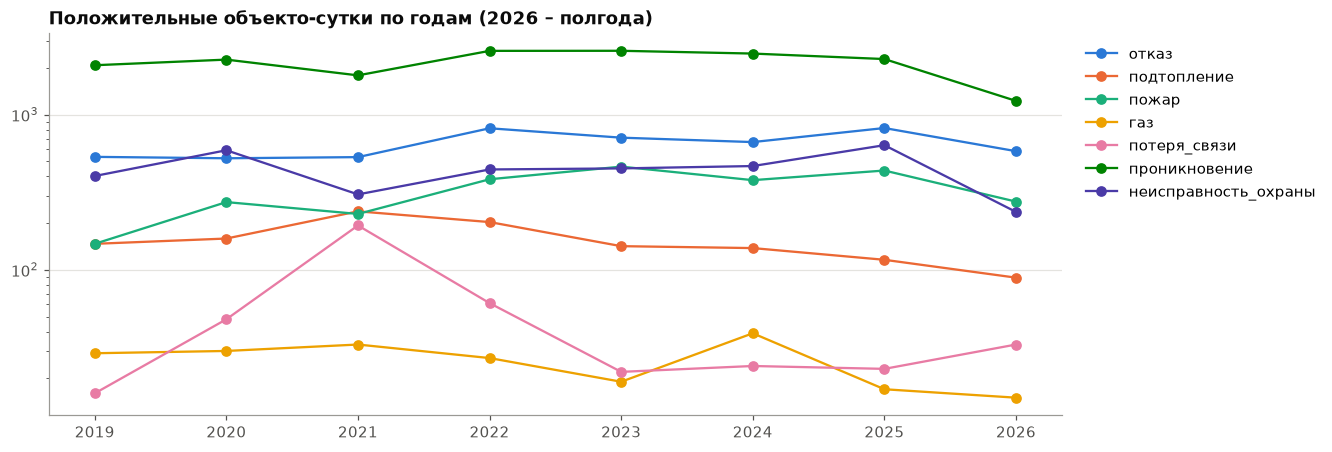

In [51]:
L = labels[clean].copy()
L["год"] = L["день"].dt.year
per_year = L.groupby("год")[TARGETS].sum().T
per_year["всего"] = per_year.sum(axis=1)
display(per_year)
cls_tab = pd.DataFrame({
    "доля_положительных": L[TARGETS].mean(),
    "объектов_с_положительным": (L.groupby("ид_объект")[TARGETS].max() > 0).sum(),
    "объектов_всего": L["ид_объект"].nunique(),
})
display(cls_tab)
fig, ax = plt.subplots(figsize=(12, 4))
for i, c in enumerate(TARGETS[:-1]):
    ax.plot(per_year.columns[:-1], per_year.loc[c].iloc[:-1], marker="o", label=c.replace("цель_", ""))
ax.set_yscale("log")
ax.set_title("Положительные объекто-сутки по годам (2026 – полгода)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

**Результат.** Отказ – самый массовый из прогнозных классов: 3,0 % объекто-суток, на 77 объектах из 78,
от 523 до 819 положительных объекто-суток за полный год. Пожар – 1,5 % (30 объектов), подтопление – 0,7 %
(24 объекта), газ – 0,1 % (18 объектов, 17-39 дней в год после маски работ), потеря связи – 0,2 % (29 объектов),
неисправность охраны – 2,1 % (47 объектов). По годам ни один класс не пропадает и не взрывается; потеря связи
выделяется 2021 годом (193 объекто-суток при 16-61 в другие годы). Любой инцидент – 5,0 % объекто-суток.

**Неисправность охраны.** Состояние «Много неисправных устройств» пишет канал «Состояние охраны» – сводный
сигнал охранной системы объекта, а не конкретный датчик или агрегат. По смыслу словаря это отказ, но в отказ
мы его не включаем и держим отдельным классом. Проверим, оправдано ли это: какую часть отказов он бы составил,
когда он возникает и можно ли по нему указать место.

In [52]:
guard = final_eps[final_eps["класс"] == "неисправность_охраны"].copy()
fault_or_guard = final_eps["класс"].isin(["отказ", "неисправность_охраны"])
print(f"эпизодов «неисправность охраны» не короче {T_FLAP} с: {n(len(guard))}, это "
      f"{len(guard) / fault_or_guard.sum():.1%} эпизодов «отказ + неисправность охраны»; "
      f"каналов {guard['ид_канала_данных'].nunique()}, объектов {guard['ид_объект'].nunique()}, "
      f"типы датчиков: {guard['тип_датчика'].value_counts().to_dict()}")
either = L[["цель_отказ", "цель_неисправность_охраны"]].max(axis=1).astype(bool)
g_day = L["цель_неисправность_охраны"].astype(bool)
print(f"объекто-суток с отказом или неисправностью охраны: {n(either.sum())}; из них с неисправностью охраны "
      f"{(g_day & either).sum() / either.sum():.1%}, только с ней (без отказа) {(g_day & ~L['цель_отказ'].astype(bool)).sum() / either.sum():.1%}")
work = lambda d: ((d["начало"].dt.dayofweek < 5) & d["начало"].dt.hour.between(8, 17)).mean()
print(f"в рабочее время (пн-пт 8:00-17:59): неисправность охраны {work(guard):.1%}, "
      f"отказ {work(final_eps[final_eps['класс'] == 'отказ']):.1%} (доля рабочего времени в неделе "
      f"{WORK_SHARE_OF_WEEK:.1%}); эпизодов неисправности охраны с пикетом: {guard['пикет'].notna().mean():.1%}")

эпизодов «неисправность охраны» не короче 60 с: 5 897, это 0.8% эпизодов «отказ + неисправность охраны»; каналов 47, объектов 47, типы датчиков: {'Состояние охраны': 5897}
объекто-суток с отказом или неисправностью охраны: 8 498; из них с неисправностью охраны 41.5%, только с ней (без отказа) 39.0%
в рабочее время (пн-пт 8:00-17:59): неисправность охраны 50.8%, отказ 33.7% (доля рабочего времени в неделе 29.8%); эпизодов неисправности охраны с пикетом: 17.3%


**Результат.** Эпизодов неисправности охраны длиннее минуты – 5 897, на 47 объектах, по одному каналу
«Состояние охраны» на объект. По числу эпизодов это всего 0,8 % от «отказа + неисправности охраны», потому
что отказы дымовых датчиков болтливы и дают сотни эпизодов в день. Но для целевой важны объекто-сутки, и
там картина обратная: из 8 498 объекто-суток с отказом или неисправностью охраны в 41,5 % есть неисправность
охраны, а в 39,0 % она единственная причина. Включи мы ее в отказ, больше трети положительных дней «отказа»
означали бы сводный сигнал охранной системы, а не поломку насоса, вентилятора или датчика. Место по ней
указать почти нельзя: пикет есть у 17,3 % эпизодов (у отказа – у 89,7 % положительных дней, раздел 7.3).
Половина эпизодов (50,8 %) начинается в рабочее время – заметно чаще, чем отказ (33,7 %) и чем доля рабочего
времени в неделе (29,8 %), то есть часть из них, вероятно, связана с работами на объекте.

Как это сказывается на предсказуемости, проверим в разделе 8. Пока держим неисправность охраны отдельным
классом и не включаем в «любой инцидент».

**Проникновение.** По ТЗ для проникновения нужна поддержка верификации, а не прогноз. Проверим, похоже ли оно
вообще на прогнозируемое событие: когда начинаются его эпизоды.

In [53]:
intr = final_eps[final_eps["класс"] == "проникновение"].copy()
intr["рабочее_время"] = (intr["начало"].dt.dayofweek < 5) & intr["начало"].dt.hour.between(8, 17)
print(f"эпизодов проникновения (пары, не короче {T_FLAP} с): {n(len(intr))}, в рабочее время: "
      f"{intr['рабочее_время'].mean():.1%} (доля рабочего времени в неделе {WORK_SHARE_OF_WEEK:.1%})")
intr["тип_датчика"] = intr["ид_канала_данных"].map(channels_pd.set_index("ид_канала_данных")["тип_датчика"])
display(intr.groupby("тип_датчика").agg(эпизодов=("начало", "size"), доля_в_рабочее_время=("рабочее_время", "mean")))

эпизодов проникновения (пары, не короче 60 с): 78 225, в рабочее время: 83.9% (доля рабочего времени в неделе 29.8%)


,эпизодов,доля_в_рабочее_время
тип_датчика,,
КД АВ,78072,0.839
Стекло,153,0.830


**Результат.** 78 225 эпизодов проникновения длиннее минуты, 83,9 % – в рабочее время; почти все дает
«КД АВ» (78 072). Это открытия в рабочее время, то есть работы и проходы персонала, а не события, которые
имеет смысл прогнозировать за сутки. Проникновение сохраняем в таблице для верификации (как требует ТЗ),
но в «любой инцидент» и в прогнозные цели не включаем.

### 7.2 Сетка и горизонт
ТЗ требует горизонт не меньше 24 часов. Шаг прогноза можно выбрать разный: каждый час («что случится
в ближайшие 24 часа, считая от этого часа») или раз в сутки в 00:00. Сравним две сетки на цели «любой инцидент».
Ожидание: у почасовой сетки соседние шаги делят 23 из 24 часов окна, поэтому метки почти всегда совпадают –
примеров формально в 24 раза больше, но новой информации в них почти нет.

In [54]:
starts = pd.concat([final_eps.loc[final_eps["класс"].isin(FORECAST), ["ид_объект", "начало"]],
                    comm[["ид_объект", "начало"]]])
starts["час"] = starts["начало"].dt.floor("h")
hours = pd.date_range(START, END + pd.Timedelta(hours=23), freq="h")
seen_days = set(zip(labels.loc[clean, "ид_объект"], labels.loc[clean, "день"]))
hourly_stats, daily_stats = [], []
by_obj = dict(tuple(starts.groupby("ид_объект")))
for obj in OBJECTS:
    g = by_obj.get(obj, starts.iloc[:0])
    cnt = g["час"].value_counts().reindex(hours, fill_value=0).to_numpy()
    fwd = np.convolve(cnt[::-1], np.ones(24, dtype=int))[:len(cnt)][::-1] > 0  # есть начало в [ч, ч + 24)
    ok = np.array([(obj, d) in seen_days for d in hours.floor("D")])
    y = fwd[ok]
    hourly_stats.append((y.sum(), len(y), (y[1:] & y[:-1]).sum(), (y[1:] == y[:-1]).sum(), len(y) - 1))
yd = labels.loc[clean].sort_values(["ид_объект", "день"])
for obj, g in yd.groupby("ид_объект"):
    y = g["цель_любой_инцидент"].to_numpy().astype(bool)
    daily_stats.append((y.sum(), len(y), (y[1:] & y[:-1]).sum(), (y[1:] == y[:-1]).sum(), len(y) - 1))
cmp_rows = {}
for name, st in [("объект × час", hourly_stats), ("объект × сутки", daily_stats)]:
    pos, tot, both, same, pairs_n = np.array(st).sum(axis=0)
    cmp_rows[name] = {"шагов": tot, "доля_положительных": pos / tot,
                      "совпадение_метки_соседних_шагов": same / pairs_n,
                      "P(следующий=1 | текущий=1)": both / pos}
display(pd.DataFrame(cmp_rows).T)

,шагов,доля_положительных,совпадение_метки_соседних_шагов,P(следующий=1 | текущий=1)
объект × час,4 092 072.000,0.050,0.997,0.969
объект × сутки,170 503.000,0.050,0.930,0.299


**Результат.** На почасовой сетке соседние шаги совпадают в 99,7 % случаев, а после положительного часа
следующий положителен с вероятностью 0,969: это один и тот же инцидент, повторенный 24 раза. Шагов
в 24 раза больше (4 092 072 против 170 503), но новой информации почти нет, а оценка модели на такой
сетке завышена. На суточной сетке совпадение 93,0 % (в основном за счет пар «0-0»), после положительного дня
следующий положителен с вероятностью 0,299 – это уже в основном новые события. Доля положительных одинакова
(5,0 % на обеих сетках).

**Выбор: объект × сутки, момент прогноза 00:00, окно [день 00:00, день + 24 ч).** Горизонт ровно 24 часа
удовлетворяет требованию ТЗ, суточный прогноз удобен для сменного планирования диспетчера, а признаки для
этапа 3 берутся строго до 00:00 дня прогноза.

### 7.3 Локация
ТЗ требует указать место. Объект есть у всех эпизодов (каналы вне справочника исключены). Пикет есть не у всех
каналов. Для каждого класса – доля положительных объекто-суток, где хотя бы у одного эпизода дня есть пикет.

In [55]:
loc = final_eps.assign(день=final_eps["начало"].dt.floor("D"), есть_пикет=final_eps["пикет"].notna())
loc_tab = loc.groupby(["класс", "ид_объект", "день"])["есть_пикет"].any().groupby("класс").mean()
display(loc_tab.rename("доля_объекто_суток_с_пикетом").to_frame().T)
PICKETS = (loc.loc[loc["класс"].isin(FORECAST) & loc["есть_пикет"]]
           .groupby(["ид_объект", "день"])["пикет"].apply(lambda s: sorted(set(s))).rename("пикеты"))
print(f"положительных объекто-суток «любой инцидент» с хотя бы одним пикетом: "
      f"{PICKETS.shape[0] / labels['цель_любой_инцидент'].sum():.1%}")

класс,вывод_из_работы,газ,неисправность_охраны,отказ,откачка,подтопление,пожар,проникновение
доля_объекто_суток_с_пикетом,0.962,0.966,0.162,0.897,0.967,0.835,0.794,0.996


положительных объекто-суток «любой инцидент» с хотя бы одним пикетом: 82.9%


**Результат.** Пикет есть у 96,6 % положительных объекто-суток газа, 89,7 % отказа, 83,5 % подтопления и
79,4 % пожара, а у неисправности охраны – только у 16,2 %: канал «Состояние охраны» относится ко всему объекту.
Для 82,9 % положительных объекто-суток «любого инцидента» есть хотя бы один пикет; список пикетов дня
сохраняется в столбце `пикеты`. Локация в прогнозе – объект всегда и пикет, где он известен.

## 8. Предсказуемость

Последний и главный критерий: можно ли вообще прогнозировать цель на сутки вперед. Те же две проверки, что
в разделе 6.4 (функция `predictability`), на сетке «объект × сутки», маскированные дни исключены:
- **подъем вероятности**: во сколько раз вероятность положительного дня выше, если на объекте этот класс уже
  был за последние 7 дней: P(y = 1 | был за 7 дней) / P(y = 1). Значение 1 – прошлое ничего не говорит о будущем;
- **частотный прогноз** «доля дней с этим классом на объекте за прошлые 30 дней» (строго до дня прогноза)
  на 2025 году: PR-AUC (площадь под кривой точность-полнота) против доли положительных, которая
  равна PR-AUC случайного прогноза. Это же будет baseline для моделей.

Те же проверки для отвергнутых вариантов: цели по флагу и по словарю и «отказ вне контекста работ»
(без открытия двери или люка за 3 часа), чтобы выбор был подтвержден и предсказуемостью. И для неисправности
охраны: отдельно, в составе отказа и в составе «любого инцидента» – так видно, что она делает с целью.

In [56]:
def labels_from_hits(hits, cls, t=T_FLAP):
    x = hits[(hits["класс"] == cls) & (hits[f"от_{t}_с"] > 0)][["ид_объект", "день"]].drop_duplicates()
    return set(zip(x["ид_объект"], x["день"]))


variants = labels[["ид_объект", "день", "маска"] + TARGETS].copy()
for s in ("флаг", "словарь"):
    for c in ["отказ", "подтопление", "пожар", "газ"]:
        hit = labels_from_hits(HITS[s], c)
        variants[f"{c} ({s})"] = [int((o, d) in hit) for o, d in zip(variants["ид_объект"], variants["день"])]
for c in ["отказ", "пожар"]:
    for t in (0, 600):
        hit = labels_from_hits(HITS["пары"], c, t)
        variants[f"{c} от {t} с (пары)"] = [int((o, d) in hit) for o, d in zip(variants["ид_объект"], variants["день"])]
off = final_eps[~((final_eps["начало"].dt.dayofweek < 5) & final_eps["начало"].dt.hour.between(8, 17))]
for c in ["пожар", "газ", "подтопление"]:
    x = off[off["класс"] == c]
    hit = set(zip(x["ид_объект"], x["начало"].dt.floor("D")))
    variants[f"{c} вне рабочего времени (пары)"] = [int((o, d) in hit) for o, d in
                                                    zip(variants["ид_объект"], variants["день"])]
no_work = faults[~faults["открытие_за_3_ч"].fillna(False)].assign(день=lambda d: d["начало"].dt.floor("D"))
nw = set(zip(no_work["ид_объект"], no_work["день"]))
variants["отказ вне работ (пары)"] = [int((o, d) in nw) for o, d in zip(variants["ид_объект"], variants["день"])]
rows = {}
variants["отказ вместе с неисправностью охраны (пары)"] = variants[["цель_отказ", "цель_неисправность_охраны"]].max(axis=1)
variants["любой инцидент вместе с неисправностью охраны"] = variants[["цель_любой_инцидент",
                                                                       "цель_неисправность_охраны"]].max(axis=1)
for c in FORECAST + ["проникновение", "неисправность_охраны", "любой_инцидент"]:
    rows[f"{c} (пары)" if c not in ("потеря_связи", "любой_инцидент") else c] = predictability(f"цель_{c}", variants)
for col in [c for c in variants.columns if "(" in c]:
    rows[col] = predictability(col, variants)
rows["любой инцидент вместе с неисправностью охраны"] = predictability(
    "любой инцидент вместе с неисправностью охраны", variants)
pred = pd.DataFrame(rows).T
display(pred)

,доля_2019-2024,подъем_7д_2019-2024,доля_2025,подъем_7д_2025,положительных_2025,PR_AUC_2025,PR_AUC_к_доле
отказ (пары),0.029,4.486,0.031,3.859,807.000,0.162,5.342
подтопление (пары),0.008,16.247,0.004,21.405,113.000,0.055,12.977
пожар (пары),0.014,6.578,0.016,5.994,431.000,0.123,7.633
газ (пары),0.001,22.177,0.001,30.826,17.000,0.001,1.758
потеря_связи,0.003,88.869,0.001,68.932,23.000,0.015,17.052
проникновение (пары),0.106,3.947,0.085,4.109,2 273.000,0.530,6.226
неисправность_охраны (пары),0.020,4.216,0.024,3.595,635.000,0.094,3.969
любой_инцидент,0.049,2.937,0.047,2.716,1 233.000,0.173,3.735
отказ (флаг),0.027,4.942,0.027,4.554,715.000,0.174,6.500
подтопление (флаг),0.008,16.384,0.004,19.829,108.000,0.055,13.522


**Результат.**
- **Прогнозные классы прогнозируемы** лучше случайного. Подъем вероятности за 7 дней на 2025 году: отказ
  3,86, пожар 5,99, подтопление 21,41, потеря связи 68,93. PR-AUC частотного прогноза выше доли положительных
  в 5,3 раза для отказа, 7,6 – для пожара, 13,0 – для подтопления, 17,1 – для потери связи, 3,7 – для любого
  инцидента. Прошлое объекта сильно говорит о его будущем, и это нижняя планка для моделей этапа 4.
- **Газ** после маски плановых работ почти непредсказуем по истории: PR-AUC к доле 1,76 на 17 положительных
  днях 2025 года (подъем за 7 дней 30,83 держится на единичных повторах). Настоящих газовых событий вне работ
  мало, и для газа остается только фоновая частота на объекте (раздел 6.4).
- **Неисправность охраны.** Сама по себе она прогнозируется хуже прогнозных классов, кроме газа: подъем за
  7 дней 3,60, PR-AUC к доле 3,97. Если ее включить в отказ, цель заметно портится: отношение PR-AUC к доле
  падает с 5,34 до 3,10, подъем – с 3,86 до 2,27, а сама PR-AUC не растет (0,162 и с ней, и без нее), хотя
  положительных становится в 1,7 раза больше. То же с «любым инцидентом»: 3,74 без нее и 2,74 с ней. Вместе
  с разделом 7.1 (больше трети положительных дней отказа, пикет у 16 % дней, сводный сигнал без конкретного
  оборудования) это решает вопрос: **неисправность охраны – отдельная цель, в отказ и в «любой инцидент» не
  входит**. Диспетчеру она показывается как фоновый риск по частоте на объекте, как газ: сигнал полезный
  (объекты, где охрана часто сообщает о неисправностях, видны), но модель для него не строим.
- **Источник.** Подтопление и газ у пар и словаря почти совпадают. Для отказа словарь дает долю положительных
  0,143 в 2025 году (переключения фазы почти каждый день) и худшее отношение PR-AUC к доле (4,72 против 5,34
  у пар). Флаг по отказу чуть лучше пар (6,50), а по пожару заметно лучше (12,63 против 7,63), но это ночной
  пожар до смены и все подряд после нее – такая цель несопоставима между эпохами (раздел 1). Предсказуемость
  выбор пар не опровергает.
- **Порог дребезга.** Для отказа отношение PR-AUC к доле при порогах 0, 60 и 600 с – 3,55, 5,34 и 8,02, для
  пожара – 7,88, 7,63 и 7,07. У отказа отношение растет с порогом, но сама PR-AUC падает (0,298, 0,162,
  0,141), а цель при 600 с – это уже другая, более редкая цель (468 положительных дней против 807). У пожара
  порог почти ничего не меняет. Однозначного победителя нет, поэтому порог 60 с остается выбранным по смыслу.
- **Работы.** «Отказ вне работ» прогнозируется лучше (9,16 против 5,34), но убирает 31 % положительных дней
  (554 против 807) по косвенному признаку, который с отказами не связан (раздел 4). «Пожар вне рабочего
  времени» – 140 положительных объекто-суток в 2025 году, отношение 12,95; «подтопление вне рабочего
  времени» – 33 и 13,30; газ вне рабочего времени – 3. Для газа и подтопления такой цели слишком мало для
  обучения, для пожара это разумное дополнение к основной цели, если заказчик подтвердит, что дневные
  срабатывания – работы.

## 9. Разбиение по времени

Модель проверяется только на будущем относительно обучения. Рабочее разбиение: обучение 2019-2024,
валидация 2025, тест первое полугодие 2026 (журнал заканчивается 30 июня 2026). Отдельно показываем
часть после смены разметки флага: она попадает в конец валидации и в тест, и если модель опирается на
признаки из флага, качество там может просесть.

In [57]:
VALID_START, TEST_START = "2025-01-01", "2026-01-01"
labels = tg.add_split(labels, VALID_START, TEST_START)
clean = labels["маска"].isna()


def split_row(sel):
    d = labels[sel & clean]
    r = {"объекто_суток": len(d), "объектов": d["ид_объект"].nunique(),
         "замаскировано_объекто_суток": int((sel & ~clean).sum())}
    for c in TARGETS:
        r[c.replace("цель_", "положительных_")] = int(d[c].sum())
    r["доля_любой_инцидент"] = d["цель_любой_инцидент"].mean()
    return r


split_tab = pd.DataFrame({s: split_row(labels["выборка"] == s) for s in ("обучение", "валидация", "тест")}
                         | {"после смены разметки флага": split_row(labels["день"] >= FLAG_CHANGE)}).T
display(split_tab)

,объекто_суток,объектов,замаскировано_объекто_суток,положительных_отказ,положительных_подтопление,положительных_пожар,положительных_газ,положительных_потеря_связи,положительных_проникновение,положительных_неисправность_охраны,положительных_любой_инцидент,доля_любой_инцидент
обучение,130 104.000,74.000,40 872.000,3 780.000,1 027.000,1 872.000,177.000,364.000,13 749.000,2 656.000,6 336.000,0.049
валидация,26 748.000,78.000,1 722.000,819.000,116.000,436.000,17.000,23.000,2 279.000,635.000,1 249.000,0.047
тест,13 651.000,78.000,467.000,581.000,89.000,275.000,15.000,33.000,1 225.000,236.000,876.000,0.064
после смены разметки флага,18 399.000,78.000,711.000,755.000,100.000,356.000,20.000,45.000,1 624.000,333.000,1 117.000,0.061


**Результат.** В обучении 130 104 объекто-суток без масок на 74 объектах, в валидации 26 748 на 78, в тесте
13 651 на 78. Доля «любого инцидента»: 0,049, 0,047, 0,064 и 0,061 после смены разметки флага – рост в 2026
году согласуется с ростом отказов после смены (раздел 1.5). Положительных в валидации и тесте: отказ 819 и 581,
пожар 436 и 275, подтопление 116 и 89, газ 17 и 15, потеря связи 23 и 33, неисправность охраны 635 и 236.

**Какие классы моделируем.** Для честной оценки PR-AUC на отложенном периоде нужны хотя бы около сотни
положительных объекто-суток в валидации и в тесте. Этому условию удовлетворяют отказ, пожар и любой
инцидент; подтопление на границе (116 и 89): после маски плановых работ в тесте чуть меньше сотни, но класс
хорошо прогнозируется (раздел 8), поэтому его тоже прогнозирует модель, а оценку на тесте читаем с поправкой на
широкий доверительный интервал. Газ (17 и 15) и потеря связи (23 и 33) не проходят: для них на этапе 4
выдается частотная оценка по истории объекта (для потери связи она дает подъем вероятности почти в 70 раз, для
газа после маски работ почти ничего – это честный фоновый уровень).
Неисправность охраны по объему прошла бы, но по разделам 7.1 и 8 это сводный сигнал без места, который
хуже всех прогнозируется, – для нее тоже частотная оценка. Проникновение – не прогнозная цель (раздел 7.1).

## 10. Итог: целевая переменная

In [58]:
COLUMNS = ["ид_объект", "день"] + TARGETS + ["пикеты", "маска", "период_смву", "эпоха_флага", "выборка"]
target = labels.merge(PICKETS.reset_index(), on=["ид_объект", "день"], how="left")
target["пикеты"] = target["пикеты"].apply(lambda v: v if isinstance(v, list) else [])
target = target[COLUMNS]
out = target.assign(день=target["день"].dt.date)  # date, а не timestamp: без сдвига часового пояса при чтении
out.to_parquet(PROCESSED_DIR / "target.parquet", index=False)
check = spark.read.parquet(str(PROCESSED_DIR / "target.parquet"))
print(f"target.parquet: {n(check.count())} строк, столбцы: {check.columns}")
assert check.agg(F.sum("цель_отказ")).first()[0] == labels["цель_отказ"].sum()
summary = split_tab[[c for c in split_tab.columns if c.startswith("положительных_")]].T.loc[:, ["обучение", "валидация", "тест"]]
display(summary)

target.parquet: 213 564 строк, столбцы: ['ид_объект', 'день', 'цель_отказ', 'цель_подтопление', 'цель_пожар', 'цель_газ', 'цель_потеря_связи', 'цель_проникновение', 'цель_неисправность_охраны', 'цель_любой_инцидент', 'пикеты', 'маска', 'период_смву', 'эпоха_флага', 'выборка']


,обучение,валидация,тест
положительных_отказ,3 780.000,819.000,581.000
положительных_подтопление,1 027.000,116.000,89.000
положительных_пожар,1 872.000,436.000,275.000
положительных_газ,177.000,17.000,15.000
положительных_потеря_связи,364.000,23.000,33.000
положительных_проникновение,13 749.000,2 279.000,1 225.000
положительных_неисправность_охраны,2 656.000,635.000,236.000
положительных_любой_инцидент,6 336.000,1 249.000,876.000


**Целевая переменная.** Единица – объект × сутки. Момент прогноза – 00:00 дня `день`, окно – [день 00:00,
день + 24 ч). `цель_<класс>` = 1, если в окне на объекте начался эпизод класса длительностью не меньше 60 с
(незакрытый эпизод считается длинным). Эпизоды – по списку тревожных пар «тип датчика + состояние»
(раздел 1.4), класс – самый важный в цепочке.

| Цель | Что это | Решение | Положительных: обучение / валидация / тест |
|---|---|---|---|
| `цель_отказ` | «Неисправен», «Обесточен» насоса и вентилятора, «Питание от батарей» ИБП и др. (13 пар) | модель | 3 780 / 819 / 581 |
| `цель_подтопление` | «Затоплен» насоса, «Не замкнут» датчика затопления | модель | 1 027 / 116 / 89 |
| `цель_пожар` | «Обнаружен дым», «Не замкнут» теплового датчика | модель | 1 872 / 436 / 275 |
| `цель_газ` | «Обнаружен газ» вне плановых работ АКМ | частотная оценка | 177 / 17 / 15 |
| `цель_потеря_связи` | пачка «Неопределен»: ≥ min(10, ½ каналов объекта) каналов в минуту, ≥ 10 мин | частотная оценка | 364 / 23 / 33 |
| `цель_неисправность_охраны` | «Состояние охраны: Много неисправных устройств» | частотная оценка, не входит в отказ и в любой инцидент | 2 656 / 635 / 236 |
| `цель_проникновение` | «Не замкнут» КД АВ и стекла | не прогноз, верификация | 13 749 / 2 279 / 1 225 |
| `цель_любой_инцидент` | отказ, подтопление, пожар, газ или потеря связи | модель | 6 336 / 1 249 / 876 |

Остальные столбцы: `пикеты` – пикеты каналов, где начались эпизоды прогнозных классов дня; `маска` – причина
исключить день или пусто: общие окна (переход СМВУ с 2021-04-21, сбой июль 2021, обрыв апрель 2024, нет
данных 2026-06-01), маски объекта по записям строго до 00:00 дня: «объект не подключен» (до дня у объекта не
было ни одной записи) и «объект не на связи» (постоянно пишущий объект, медиана больше 200 записей в сутки за
30 дней, молчал все предыдущие сутки), и «плановые работы АКМ» – окно планово-предупредительных работ
аппаратуры контроля метана ±3 суток (2026 – по графику заказчика, остальные годы – по следу тестового газа
и демонтажа в журнале, раздел 6.4); окна сохранены в `datasets/processed/maintenance/ppr_windows.parquet`. Тихий день подключенного объекта не маскируется,
это обычный отрицательный пример. `период_смву` и `эпоха_флага` – эпохи; `выборка` – обучение (2019-2024),
валидация (2025), тест (2026-01 … 2026-06).

**Критерии.**
1. **Тип.** Классы – отказ, подтопление, пожар, газ из ТЗ, плюс потеря связи; проникновение – для верификации;
   неисправность охраны – отдельный фоновый сигнал, не отказ (разделы 1.3, 7.1, 8).
2. **Реальность.** Эпизоды вместо записей, порог 60 с, маски сбоев и перехода СМВУ, исключены нормальные
   переключения (разделы 2, 3, 6). Маски объекта опираются только на то, что известно к 00:00 дня прогноза,
   и не выбрасывают тихие дни, поэтому доля положительных не завышена (раздел 6.3). Дни плановых работ
   аппаратуры контроля метана маскируются: 60 % прежних положительных дней газа были тестовым газом
   (раздел 6.4). Слабое место: пожар, газ и подтопление в 83-97 % случаев начинаются в рабочее время и,
   вероятно, во многом вызваны и другими работами, графика которых нет (раздел 4).
3. **Единообразие.** Источник не зависит от флага; эпизоды пожара после смены разметки не подскочили.
   Остается реальное изменение данных в конце октября 2025 (массовые «Неисправен» температурных и газовых
   датчиков, отказ +21 % объекто-суток) – помечено столбцом `эпоха_флага` (раздел 1.5).
4. **Локация.** Объект у всех, пикет у 82,9 % положительных дней «любого инцидента» (раздел 7.3).
5. **Объем.** Отказ, пожар и любой инцидент – не меньше 100 положительных в валидации и тесте, подтопление –
   116 и 89; газ и потеря связи – меньше, для них частотная оценка (раздел 9).
6. **Предсказуемость.** Моделируемые классы и потеря связи прогнозируемы: частотный прогноз дает PR-AUC
   в 3,7-17,1 раза выше доли положительных, неисправность охраны – в 4,0 раза; газ после маски плановых работ –
   только в 1,8 раза (раздел 8).

**Что остается открытым.** Без журнала ОДС нельзя отделить подтвержденные инциденты от ложных срабатываний,
а без графика работ бригад (кроме графика ППР аппаратуры контроля метана на 2026 год) – срабатывания из-за
работ. Окна ППР прошлых лет восстановлены по журналу с точностью по дням около 0,65 и полнотой около 0,84
(проверка на графике 2026 года); графики ППР за 2019-2025 годы проверили бы их напрямую. Эти два источника изменили бы определение пожара, газа и
подтопления сильнее всего: возможно, основной целью стал бы «пожар вне работ». Данные о связи контроллеров
позволили бы проверить, что тихий день объекта – действительно день без событий, а не незамеченный обрыв.
Причину смены разметки флага и массовых «Неисправен» с конца октября 2025 года, а также смысл сигнала
«Много неисправных устройств» и то, как с ним работает диспетчер, стоит уточнить у заказчика.